# Stitching pt12: fixed alleles, conditioned gaps and low ε

This replaces the provisional 500 kb pilot with the **completed, allele-corrected
conditioning experiment** from 14 November 2026. Simulations contain 50, 500
and 5,000 diploid individuals across chr20p (28.1 Mb), with 1% injected genotype
error and no phase error. 1KGP contains 3,202 diploid individuals. The actual
inference-site extents are shown below; unobserved chromosome flanks are excluded.
All three methods share each dataset's inferred ancestor reference. Back mutations
are represented correctly, and every saved called-allele check passed.

Scientific diagnostics use `conditioning_test_rfloor_1e20_diagnostics.tar.gz` and
`conditioning_test_control_diagnostics.tar.gz`. The control disables gap conditioning
and retains the same epsilon, map floor, focal settings, inputs and ancestor references.
**Only the performance section** uses the later
`conditioning_greedy_optimized_20261114` trials. No superseded timings are plotted.
The optimisation checks establish identical greedy edge and mutation arrays
across all eight dataset/mode comparisons. Raw outputs and source snapshots
remain intact. The replaced notebook and its saved outputs are backed up under
`data/ch5/provenance/pt12_before_20261116/`.

> **History note (16 November 2026).** The experimental TSInfer commit
> `d7670d59` ("Support a minimum recombination probability after map conversion")
> has been dropped from the local `tsls` branch rather than reverted. The branch
> now ends at `63837fd4`, retaining fixed haploid sample-size support. Production
> matching no longer offers a recombination floor; zero-rate stretches are
> assigned to HMM gaps by excluding touching focal regions. Saved trees, plots
> and the comparisons below still describe the earlier floored experiment.
> This notebook preserves that research record; reproducing the deleted floor
> implementation is not a requirement.


In [1]:
import logging
import pathlib

import pandas as pd

import IPython.display as ipython_display

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO, format="%(message)s")

In [2]:
config_path = {
    "base_dir": repository_dir,
    "data_dir": repository_dir / "data/ch5/stitching_pt12_conditioning/corrected_run",
    "cache_subdir": "analysis_20261116",
    "workers": None,
    "helper_threads": 1,
    "mutation_rate": 2.35e-8,
    "dating": {
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
    },
    "frequency_bins": {
        "cutoffs": [0.01, 0.5],
        "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
    },
}
performance_dir = (
    repository_dir.parent
    / "tsinfer-match-eval/data/performance/conditioning_greedy_optimized_20261114"
)
config = nb_utils.paramsearch_load_config(config_path)
plot_data = nb_utils.prepare_scaling_data(config)
cohort_labels = {
    "out_of_africa_n50_28_1mbp_error": "50 OOA",
    "out_of_africa_n500_28_1mbp_error": "500 OOA",
    "out_of_africa_n5000_28_1mbp_error": "5,000 OOA",
    "tgp_chr20p_n3202": "3,202 1KGP",
}
control_path = dict(config_path)
control_path["data_dir"] = (
    repository_dir / "data/ch5/stitching_pt12_conditioning/unconditioned_run"
)
control = nb_utils.paramsearch_load_config(control_path)
comparison = dict(config)
comparison["cache_dir"] = config["data_dir"].parent / "comparison_20261116"
comparison["cache_dir"].mkdir(exist_ok=True)
plot_data = nb_utils.prepare_scaling_data(comparison)
method_colors = {"full_hmm": "#555555", "greedy": "#0072B2", "unconditioned": "#D55E00"}
method_labels = {
    "full_hmm": "Full HMM",
    "greedy": "Conditioned greedy",
    "unconditioned": "Unconditioned greedy",
}

## Scientific settings and allele checks

The archived sample settings use **ε = 10⁻⁹ errors per haplotype-bp**.
With S quality-filtered source sites across L = 28,100,000 bp, the constant
sample mismatch probability is **p = εL/S**, before cohort singleton and
monomorphic inference exclusions. It is not ε itself and is not fitted here.
The resulting p values range from about 4.26 × 10⁻⁸ to 1.93 × 10⁻⁷.
For the simulated 1% error data, this is deliberately a low configured rate,
not a calibrated estimate of the injected error process.

Samples use the chr20 HapMap map with **rᵢ = (1 − exp(−2dᵢ))/2** and a
**recombination floor of 10⁻²⁰** on transitions after the first site. This
changes 4,536 / 11,936 / 30,409 transitions in the three simulations and none
in 1KGP; positive map transitions are unchanged. The floor is a modelling
change: it permits switching where the original map was exactly zero.
A captured 258-site simulated gap had different pinned endpoints and zero
recombination throughout, so its two-sided constraint was impossible without
such a change. Likelihood flooring and both pruning thresholds are **zero**.
Ancestors retain their stock native probabilities, without the sample map or
sample ε. These runs therefore do not apply the low ε to ancestor inference.

Residual greedy gaps condition on available left/right focal parents; exact
focal copying remains fixed. Supported one-site gaps retain the direct-copy
rule. AF cutoffs are 0.1 / 0.05 / 0.05 / 0.05 and minimum focal lengths are
25 / 50 / 100 / 150 kb (mean-density site-count equivalents).
Disabling conditioning removes endpoint pins and the extra flanking sites
from residual HMM windows; the fixed focal cover and supported one-site
direct-copy rule remain the same. Full HMM is the unconstrained whole-span sample comparison. The matched unconditioned-greedy control isolates gap conditioning at fixed ε.
There is no ε sweep, so these results do not isolate the effect of changing ε.

In [3]:
if __name__ == "__main__":
    cohorts = nb_utils.cohort_table(config)
    ipython_display.display(cohorts)
    settings = nb_utils.conditioning_review_settings(config)
    ipython_display.display(settings)
    allele_checks = nb_utils.conditioning_review_quality(config)
    ipython_display.display(allele_checks)
    control_settings = nb_utils.conditioning_review_settings(control)
    ipython_display.display(control_settings)
    input_checks = nb_utils.conditioning_review_control_inputs(config, control)
    ipython_display.display(input_checks)

,dataset,num_samples,num_haplotypes,num_sites,analysis_span_mb,has_truth,min_region_size_kb,min_focal_region_size
0,out_of_africa_n50_28_1mbp_error,50,100,94665,28.017828,True,25,84
1,out_of_africa_n500_28_1mbp_error,500,1000,207968,28.018744,True,50,371
2,tgp_chr20p_n3202,3202,6404,580909,26.047226,False,150,3345
3,out_of_africa_n5000_28_1mbp_error,5000,10000,490670,28.018831,True,100,1751


,dataset,haploid_sample_size,condition_gaps,epsilon_per_haplotype_bp,calibration_span_bp,mismatch_probability,recombination_floor,floored_transitions,mismatch_cost,median_switch_cost,maximum_switch_cost
0,out_of_africa_n50_28_1mbp_error,100,True,1.000000e-09,28100000,1.929866e-07,1.000000e-20,4536,15.460645,19.202634,50.656872
1,out_of_africa_n500_28_1mbp_error,1000,True,1.000000e-09,28100000,8.836811e-08,1.000000e-20,11936,16.241755,22.266587,52.959457
2,out_of_africa_n5000_28_1mbp_error,10000,True,1.000000e-09,28100000,4.255744e-08,1.000000e-20,30409,16.972411,25.446708,55.262042
3,tgp_chr20p_n3202,6404,True,1.000000e-09,28100000,4.480815e-08,1.000000e-20,0,16.920876,25.052418,35.264308


,run_id,status,called_allele_errors,haplotypes
0,out_of_africa_n50_28_1mbp_error_from_reference...,ok,0,100
1,out_of_africa_n50_28_1mbp_error_from_reference...,ok,0,100
2,out_of_africa_n50_28_1mbp_error_resident_match...,ok,0,100
3,out_of_africa_n50_28_1mbp_error_resident_match...,ok,0,100
4,out_of_africa_n500_28_1mbp_error_from_referenc...,ok,0,1000
5,out_of_africa_n500_28_1mbp_error_from_referenc...,ok,0,1000
6,out_of_africa_n500_28_1mbp_error_resident_matc...,ok,0,1000
7,out_of_africa_n500_28_1mbp_error_resident_matc...,ok,0,1000
8,out_of_africa_n5000_28_1mbp_error_from_referen...,ok,0,10000
9,out_of_africa_n5000_28_1mbp_error_from_referen...,ok,0,10000


,dataset,haploid_sample_size,condition_gaps,epsilon_per_haplotype_bp,calibration_span_bp,mismatch_probability,recombination_floor,floored_transitions,mismatch_cost,median_switch_cost,maximum_switch_cost
0,out_of_africa_n50_28_1mbp_error,100,False,1.000000e-09,28100000,1.929866e-07,1.000000e-20,4536,15.460645,19.202634,50.656872
1,out_of_africa_n500_28_1mbp_error,1000,False,1.000000e-09,28100000,8.836811e-08,1.000000e-20,11936,16.241755,22.266587,52.959457
2,out_of_africa_n5000_28_1mbp_error,10000,False,1.000000e-09,28100000,4.255744e-08,1.000000e-20,30409,16.972411,25.446708,55.262042
3,tgp_chr20p_n3202,6404,False,1.000000e-09,28100000,4.480815e-08,1.000000e-20,0,16.920876,25.052418,35.264308


,dataset,same_inputs_and_full_paths
0,out_of_africa_n50_28_1mbp_error,True
1,out_of_africa_n500_28_1mbp_error,True
2,out_of_africa_n5000_28_1mbp_error,True
3,tgp_chr20p_n3202,True


## Saved path weights, mismatches and additional switches

At each inference-site boundary, staying on the same parent has weight
`Sᵢ = 1 − rᵢ + rᵢ/n` and switching to a particular parent has weight
`rᵢ/n`, using the archived map and floor and the haploid cohort size `n`.
At each observed site, copying the called allele has weight `1 − p` and a
mismatch has weight `p`. Missing calls contribute zero log emission weight.

The split in **Cost of the saved greedy paths** uses Full HMM minus greedy
for each haplotype. For the transition part, sum `log[(rᵢ/n)/Sᵢ]` over the
boundaries where each saved path changes parent, then subtract the greedy
sum from the Full HMM sum. For the emission part, multiply each path's
terminal sample mutation count (including reversions) by `log[p/(1 − p)]`
and take the same difference. Average both differences across haplotypes.
Positive values increase the greedy cost. The two contributions add to the
total extra negative log weight relative to Full HMM.

The total log-weight panel adds back the shared all-stay sum and the
all-match log weight over called inference sites. It scores the saved
path conditional on its initial parent. The extra-switch percentage is
calculated for each haplotype with a nonzero Full HMM switch count and then
averaged, following pt13. Focal coverage uses the shared masks and the
same population groups as pt13. Error bars show one haplotype SEM.

,dataset,delta_log_path_odds,delta_switch_log_odds,delta_mismatch_log_odds,full_switches,stitched_switches,num_extra_switches,full_focal_switches,stitched_focal_switches,full_gap_switches,stitched_gap_switches,full_seam_switches,stitched_seam_switches,sample_mutations_full,sample_mutations_greedy,extra_sample_mutations,focal_coverage_percentage,parent_agreement_percentage,haplotypes,fraction_extra_mutations,fraction_extra_switches,conditioning
0,out_of_africa_n50_28_1mbp_error,-3628.9555,-4553.5021,924.5466,416.4100,580.8900,164.4800,298.5700,340.7100,97.8600,102.9200,19.9800,137.2600,202.1200,142.3200,-59.8000,83.7716,62.8253,100,0.0000,1.0,greedy
1,out_of_africa_n500_28_1mbp_error,-4049.5068,-4967.8969,918.3900,165.9270,351.9700,186.0430,119.6410,216.0920,43.2360,55.4680,3.0500,80.4100,210.4580,153.9130,-56.5450,84.0391,44.6683,1000,0.0000,1.0,greedy
2,out_of_africa_n5000_28_1mbp_error,-3904.9159,-4776.2133,871.2974,63.1558,240.2228,177.0670,39.4872,140.0961,23.2677,45.3620,0.4009,54.7647,206.4798,155.1437,-51.3361,76.7132,28.0141,10000,0.0000,1.0,greedy
3,tgp_chr20p_n3202,-1582.3604,-2033.4613,451.1009,131.1622,203.3968,72.2345,66.4507,102.7695,63.8609,64.1622,0.8507,36.4650,86.2931,59.6337,-26.6594,82.6161,61.8849,6404,0.0003,1.0,greedy
4,out_of_africa_n50_28_1mbp_error,-4100.1723,-5521.9332,1421.7609,416.4100,629.6700,213.2600,298.5700,340.7100,97.8600,97.7500,19.9800,191.2100,202.1200,110.1600,-91.9600,83.7716,61.3319,100,0.0000,1.0,unconditioned
5,out_of_africa_n500_28_1mbp_error,-4700.4508,-6081.1623,1380.7116,165.9270,396.0250,230.0980,119.6410,216.0920,43.2360,40.0900,3.0500,139.8430,210.4580,125.4480,-85.0100,84.0391,43.3516,1000,0.0000,1.0,unconditioned
6,out_of_africa_n5000_28_1mbp_error,-4488.6100,-5686.5805,1197.9705,63.1558,270.2548,207.0990,39.4872,140.0961,23.2677,20.2523,0.4009,109.9064,206.4798,135.8964,-70.5834,76.7132,27.7831,10000,0.0000,1.0,unconditioned
7,tgp_chr20p_n3202,-1695.2377,-2241.0390,545.8013,131.1622,211.0381,79.8759,66.4507,102.7695,63.8609,59.7419,0.8507,48.5267,86.2931,54.0370,-32.2561,82.6161,61.4933,6404,0.0000,1.0,unconditioned


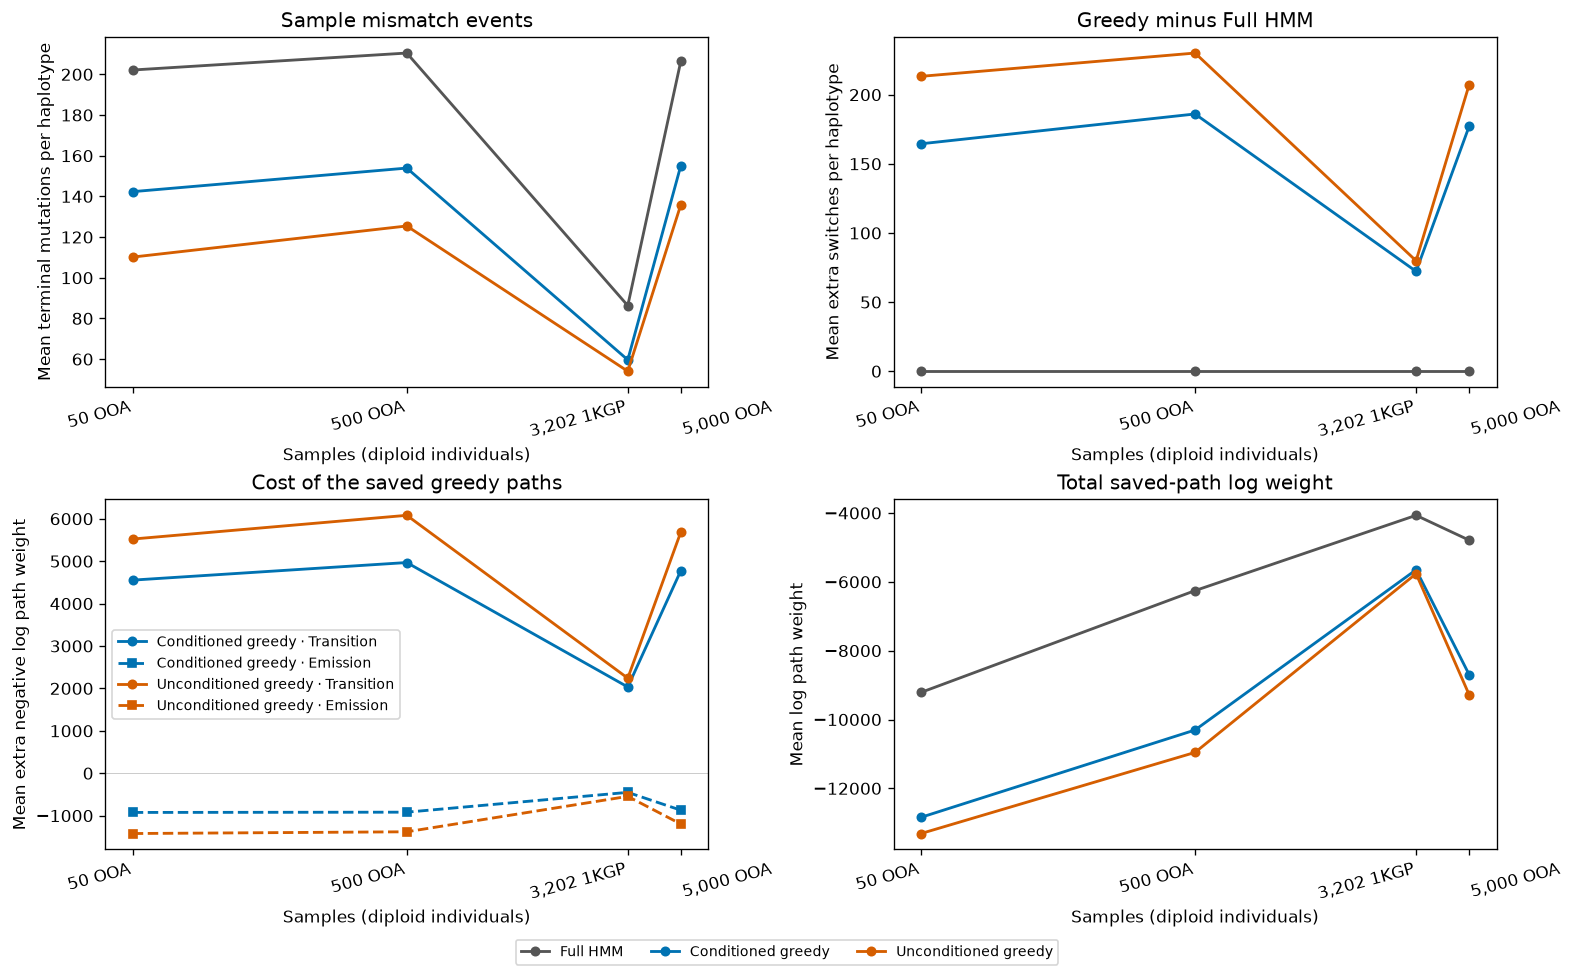

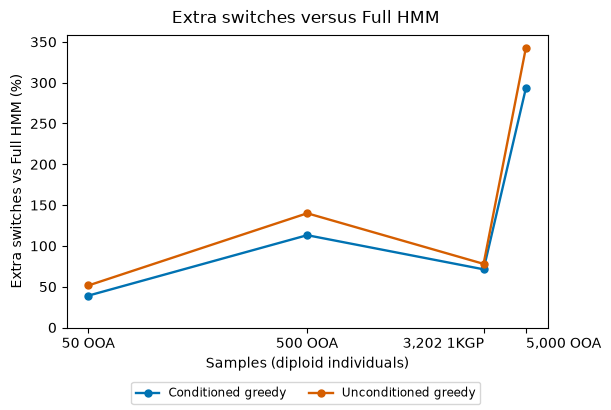

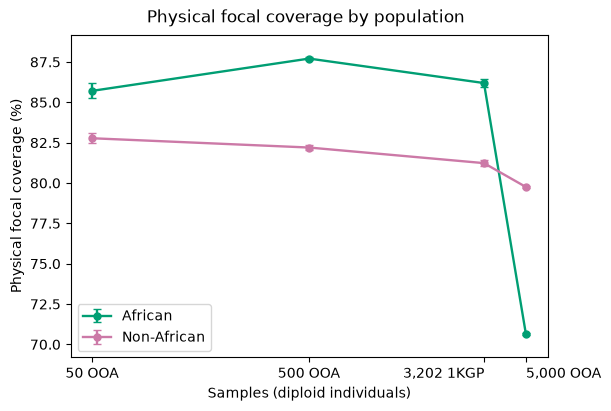

In [4]:
if __name__ == "__main__":
    paired_paths = nb_utils.conditioning_review_paths(config)
    paired_paths["conditioning"] = "greedy"
    control_paths = nb_utils.conditioning_review_paths(control)
    control_paths["conditioning"] = "unconditioned"
    paired_paths = pd.concat([paired_paths, control_paths], ignore_index=True)
    summaries = []
    for method, frame in paired_paths.groupby("conditioning", sort=False):
        summary = nb_utils.conditioning_review_summary(frame)
        summary["conditioning"] = method
        summaries.append(summary)
    path_summary = pd.concat(summaries, ignore_index=True)
    paired_paths.to_csv(
        comparison["cache_dir"] / "paired_path_diagnostics.csv", index=False
    )
    path_summary.to_csv(comparison["cache_dir"] / "path_summary.csv", index=False)
    ipython_display.display(path_summary.round(4))
    path_plot_summary = nb_utils.conditioning_path_plot_summary(
        dict(config, cache_dir=comparison["cache_dir"]), paired_paths
    )
    path_plot_summary.to_csv(
        comparison["cache_dir"] / "path_plot_summary.csv", index=False
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_conditioning_review_paths(
            plot_data,
            path_plot_summary,
            cohort_labels=cohort_labels,
            figsize=(13, 8),
            dpi=120,
            method_colors=method_colors,
            method_labels=method_labels,
            sample_tick_rotation=15,
        ),
        "conditioned_path_costs",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            path_plot_summary,
            metrics={"switch_increase_percentage": "Extra switches vs Full HMM (%)"},
            title="Extra switches versus Full HMM",
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            panel_width=6,
            panel_height=4,
        ),
        "extra_switches_scaling",
        export_dpi=180,
    )
    coverage_config = dict(
        config,
        cache_dir=comparison["cache_dir"],
        population_groups={
            "African": ["YRI", "AFR"],
            "Non-African": ["CEU", "CHB", "EUR", "EAS", "SAS", "AMR"],
        },
    )
    population_coverage = nb_utils.population_coverage(coverage_config)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_coverage(
            plot_data,
            population_coverage,
            cohort_labels=cohort_labels,
            population_colors={"African": "#009E73", "Non-African": "#CC79A7"},
            panel_width=6,
            panel_height=4,
        ),
        "focal_population_coverage",
        export_dpi=180,
    )

## Direct ultimate-root to sample edges

Count raw edges from the ultimate ancestor (the child of the vestigial root)
to sample haplotypes over each cohort's common observed extent. Each edge
counts once. Its span is clipped to the analysis interval. Counts and summed
spans are divided by the number of haplotypes. The log-scale bars show totals.

Using the shared focal masks, an edge is classified as a focal/gap seam if it
overlaps a gap and touches an internal boundary. The other categories are gap
interior and focal only. The signed panels subtract unconditioned from
conditioned greedy; diamonds show the net difference across categories.
The histograms use common log-spaced bins and show edges per haplotype per bin.

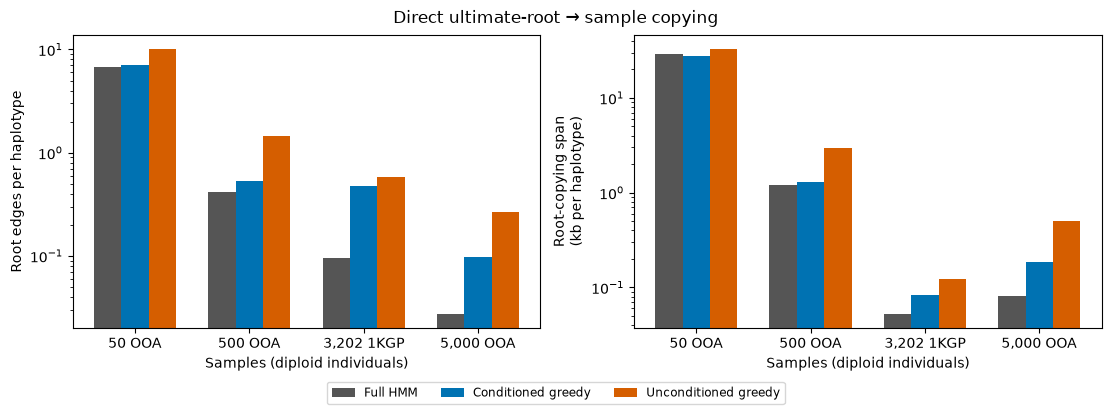

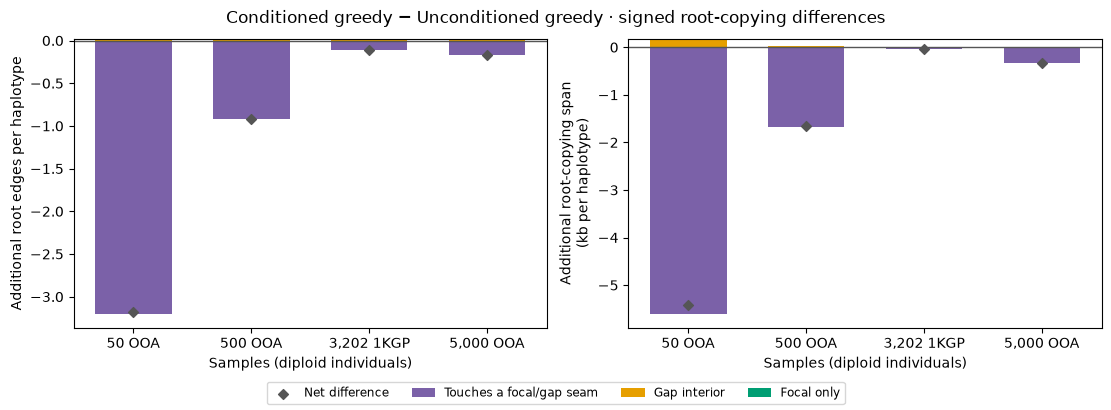

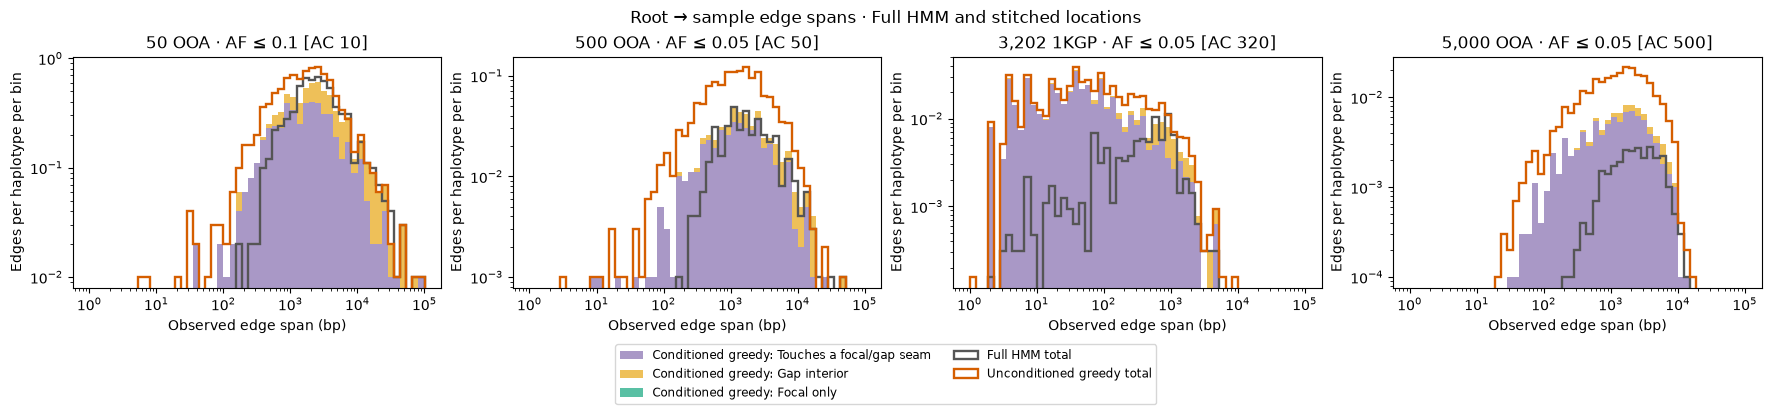

In [12]:
if __name__ == "__main__":
    diagnostic_dir = comparison["cache_dir"] / "root_edges_and_recurrence"
    diagnostic_dir.mkdir(exist_ok=True)
    root_config = dict(config, cache_dir=diagnostic_dir / "conditioned")
    root_control = dict(control, cache_dir=diagnostic_dir / "unconditioned")
    diagnostic_config = dict(comparison, cache_dir=diagnostic_dir)
    diagnostic_plots = nb_utils.prepare_scaling_data(diagnostic_config)
    root_plot_data = nb_utils.prepare_scaling_data(root_config)

    root_edges = nb_utils.root_edge_summary(root_config)
    control_edges = nb_utils.root_edge_summary(root_control)
    control_edges = control_edges.loc[control_edges.method.eq("greedy")].copy()
    control_edges["method"] = "unconditioned"
    root_edges = pd.concat([root_edges, control_edges], ignore_index=True)
    root_edges.to_csv(diagnostic_dir / "root_edge_summary.csv", index=False)
    root_edge_categories = {
        "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
        "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
        "focal": {"label": "Focal only", "color": "#009E73"},
    }
    nb_plot.save_cohort_figure(
        diagnostic_plots,
        nb_plot.plot_root_totals(
            root_plot_data,
            root_edges,
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            stacked=False,
            grouped_bar_width=0.24,
            log_y=True,
            panel_width=5.5,
            panel_height=4.0,
        ),
        "root_edges_counts_spans",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        diagnostic_plots,
        nb_plot.plot_root_edge_differences(
            root_plot_data,
            root_edges,
            comparison_methods=("greedy", "unconditioned"),
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            root_edge_categories=root_edge_categories,
            panel_width=5.5,
            panel_height=4.0,
        ),
        "root_edges_conditioning_difference",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        diagnostic_plots,
        nb_plot.plot_root_edge_spans(
            root_plot_data,
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            root_edge_categories=root_edge_categories,
            additional_method_cache_dirs={"unconditioned": root_control["cache_dir"]},
            root_edge_histogram_bins=55,
            panel_width=4.4,
            panel_height=4.0,
        ),
        "root_edges_span_histograms",
        export_dpi=180,
    )

## Recurrent mutations on the common inference-site axis

A recurrent site has at least two mutation records, including reversions.
The denominator is every inference site, and the conditional mean includes
the first mutation. Counts use **raw** reference-plus-sample trees before
simplification or dating. Truth uses the identical simulated inference-site
positions. The raw methods share their reference mutations, so differences
reflect sample matching; recurrent sites themselves need not be genotype
errors. Real 1KGP has no mutation truth panel.

,dataset,method,af_cutoff,num_sites,recurrent_sites,recurrent_site_percentage,mutations_at_recurrent_sites,mean_mutations_per_recurrent_site,additional_mutations,num_samples
0,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94665,15103,15.954154,35315,2.338277,20212,50
1,out_of_africa_n50_28_1mbp_error,greedy,0.10,94665,11393,12.035071,25625,2.249188,14232,50
2,out_of_africa_n50_28_1mbp_error,truth,NaN,94665,337,0.355992,675,2.002967,338,50
3,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207968,91457,43.976477,301915,3.301169,210458,500
4,out_of_africa_n500_28_1mbp_error,greedy,0.05,207968,58224,27.996615,212137,3.643463,153913,500
5,out_of_africa_n500_28_1mbp_error,truth,NaN,207968,1787,0.859267,3578,2.002238,1791,500
6,tgp_chr20p_n3202,full_hmm,NaN,580909,201856,34.748300,754477,3.737699,552621,3202
7,tgp_chr20p_n3202,greedy,0.05,580909,138884,23.908048,520778,3.749734,381894,3202
8,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490670,338149,68.915768,2402947,7.106178,2064798,5000
9,out_of_africa_n5000_28_1mbp_error,greedy,0.05,490670,193844,39.505982,1745281,9.003534,1551437,5000


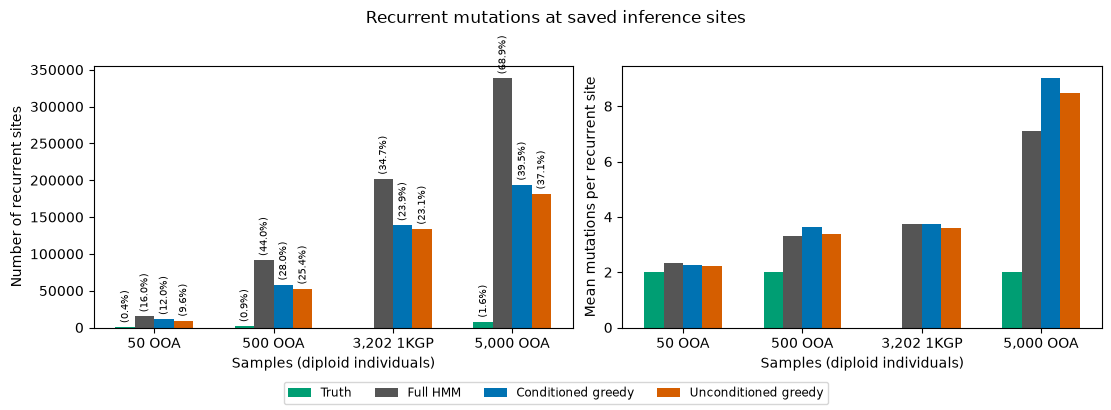

In [5]:
if __name__ == "__main__":
    recurrence = nb_utils.recurrent_sites(config)
    control_recurrence = nb_utils.recurrent_sites(control)
    control_recurrence = control_recurrence.loc[
        control_recurrence.method.eq("greedy")
    ].copy()
    control_recurrence["method"] = "unconditioned"
    recurrence = pd.concat([recurrence, control_recurrence], ignore_index=True)
    recurrence.to_csv(
        comparison["cache_dir"] / "recurrent_site_summary.csv", index=False
    )
    ipython_display.display(recurrence)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_recurrence(
            plot_data,
            recurrence,
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            panel_width=5.5,
            panel_height=4.0,
            stage_label_margin=0.3,
        ),
        "conditioned_recurrent_sites",
        export_dpi=180,
    )

## Precision and recall of inferred recurrent sites

Following [Chapter 4's epsilon analysis](../ch4/epsilon_testing.ipynb), we
evaluate the same inference sites for all three methods. At each simulated
site, we first pool the two sources of truth by taking their **union**. A
site is truth-positive if it has at least two mutation records in the
simulated tree sequence or at least one injected genotype error, using the
source store's per-site error count. A site with both counts once.

A prediction is positive if the raw inferred tree sequence has at least
two mutation records at that site, including back mutations. We match by
position regardless of which samples carry the mutations or errors. An
inferred site with multiple affected samples still contributes one site.
Precision is
the fraction of predicted positives in the pooled truth set. Recall is the
fraction of the pooled truth set flagged by inferred recurrence. These are
site-level scores for the three simulations. 1KGP has no truth labels.

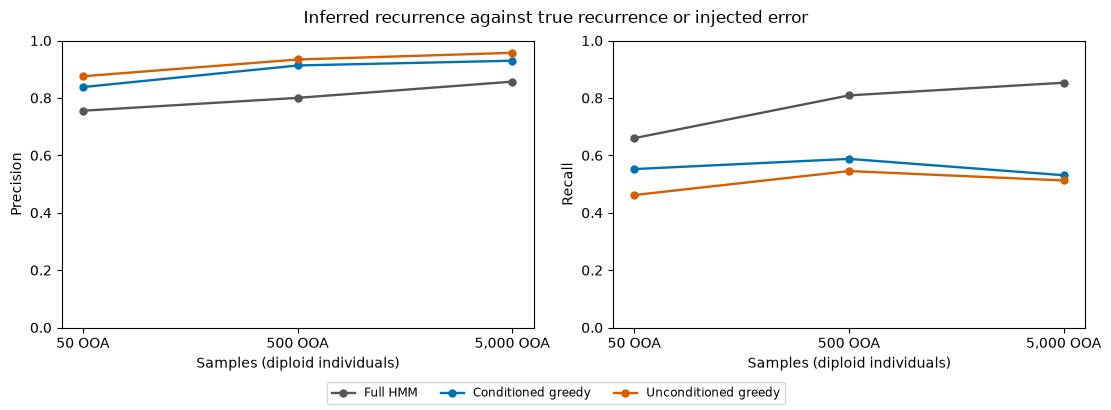

In [13]:
if __name__ == "__main__":
    recurrence_scores = nb_utils.conditioning_recurrence_scores(config, control)
    recurrence_scores.to_csv(
        diagnostic_dir / "recurrent_site_precision_recall.csv", index=False
    )
    nb_plot.save_cohort_figure(
        diagnostic_plots,
        nb_plot.plot_scaling(
            diagnostic_plots,
            recurrence_scores,
            metrics={"precision": "Precision", "recall": "Recall"},
            title="Inferred recurrence against true recurrence or injected error",
            include_full=True,
            datasets=recurrence_scores.dataset.unique(),
            y_limits=(0, 1),
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            sample_tick_alignments={},
            panel_width=5.5,
            panel_height=4.0,
        ),
        "recurrent_site_precision_recall",
        export_dpi=180,
    )

## Inferred allele ages against Full HMM and simulation truth

Date all three saved inferred sample genealogies with tsdate variational gamma,
mutation rate 2.35 × 10⁻⁸ per bp per generation, after the same post-processing
and preprocessing used by pt13. Matching is not rerun. Dates are posterior
mutation means in generations; true mutation times come from the simulations.
Reference ancestor times are not themselves these inferred allele ages.

Each cohort uses **one common position/ancestral-allele/derived-allele
intersection across all three methods and truth where available**. Only finite,
single-mutation sites have a unique pairing. Recurrent sites are therefore
excluded from age comparisons and analysed separately above. Retention counts
below show this selection. DAF bins use Full HMM frequencies for all methods.
Pearson r, Spearman ρ, signed mean age error and median absolute age error
are reported; correlation alone does not establish age accuracy.
1KGP compares both greedy methods with Full HMM only. Hexbin display limits clip the
99.9th percentile for readability; statistics retain all matched mutations.

,dataset,method,af_cutoff,finite_single_mutation_sites,common_mutations,retained_percentage
0,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,79561,77194,97.024924
1,out_of_africa_n50_28_1mbp_error,greedy,0.10,83271,77194,92.702141
2,out_of_africa_n50_28_1mbp_error,unconditioned,0.10,85547,77194,90.235777
3,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,116511,110269,94.642566
4,out_of_africa_n500_28_1mbp_error,greedy,0.05,149743,110269,73.638835
5,out_of_africa_n500_28_1mbp_error,unconditioned,0.05,155147,110269,71.073885
6,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,152520,136189,89.292552
7,out_of_africa_n5000_28_1mbp_error,greedy,0.05,296826,136189,45.881762
8,out_of_africa_n5000_28_1mbp_error,unconditioned,0.05,308854,136189,44.094945
9,tgp_chr20p_n3202,full_hmm,NaN,379052,368928,97.329126


,dataset,num_samples,method,af_cutoff,reference_method,frequency_bin,matched_mutations,pearson_r,spearman_r,mean_error_generations,median_absolute_error_generations,mean_estimated_age,mean_reference_age
0,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,all,77194,0.7260,0.8530,-968.0750,2032.5827,10074.4159,11042.4908
1,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,DAF < 0.01,0,NaN,NaN,NaN,NaN,NaN,NaN
2,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,0.01 ≤ DAF < 0.5,66009,0.6991,0.8163,-1073.7705,1669.5811,7467.9929,8541.7634
3,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,DAF ≥ 0.5,11185,0.4966,0.6251,-344.3061,6258.8047,25456.3892,25800.6953
4,out_of_africa_n50_28_1mbp_error,50,greedy,0.10,truth,all,77194,0.7261,0.8520,-1052.3921,2070.0698,9990.0987,11042.4908
...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,tgp_chr20p_n3202,3202,greedy,0.05,full_hmm,DAF ≥ 0.5,27608,0.9852,0.9972,157.1406,868.6710,128720.0808,128562.9402
64,tgp_chr20p_n3202,3202,unconditioned,0.05,full_hmm,all,368928,0.9610,0.9835,-153.4711,61.1481,13815.5166,13968.9877
65,tgp_chr20p_n3202,3202,unconditioned,0.05,full_hmm,DAF < 0.01,286547,0.8992,0.9667,-162.8560,50.5396,2490.8571,2653.7130
66,tgp_chr20p_n3202,3202,unconditioned,0.05,full_hmm,0.01 ≤ DAF < 0.5,54773,0.9911,0.9884,-23.2027,307.3983,15381.6781,15404.8808


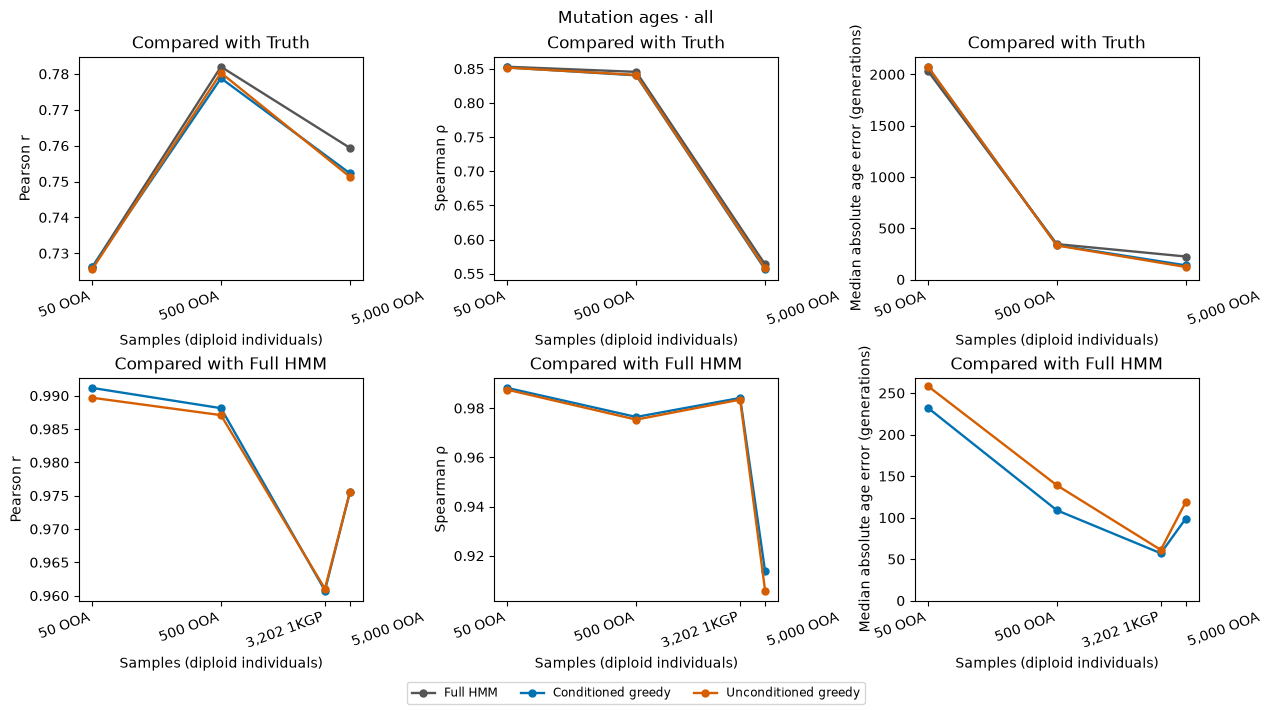

In [6]:
if __name__ == "__main__":
    dated = nb_utils.perf_scaling_date_all(config)
    control_dated = nb_utils.conditioning_review_date_control(control)
    dated = pd.concat([dated, control_dated], ignore_index=True)
    age_correlations = nb_utils.perf_scaling_mutation_correlations(comparison, dated)
    retention = nb_utils.conditioning_review_age_retention(comparison)
    ipython_display.display(retention)
    ipython_display.display(age_correlations.round(4))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_correlations(
            plot_data,
            age_correlations,
            frequency_bin="all",
            metrics={
                "pearson_r": "Pearson r",
                "spearman_r": "Spearman ρ",
                "median_absolute_error_generations": "Median absolute age error (generations)",
            },
            cohort_labels=cohort_labels,
            method_colors=method_colors,
            method_labels=method_labels,
            panel_width=4.2,
            panel_height=3.5,
            sample_tick_rotation=20,
        ),
        "conditioned_age_correlations",
        export_dpi=180,
    )

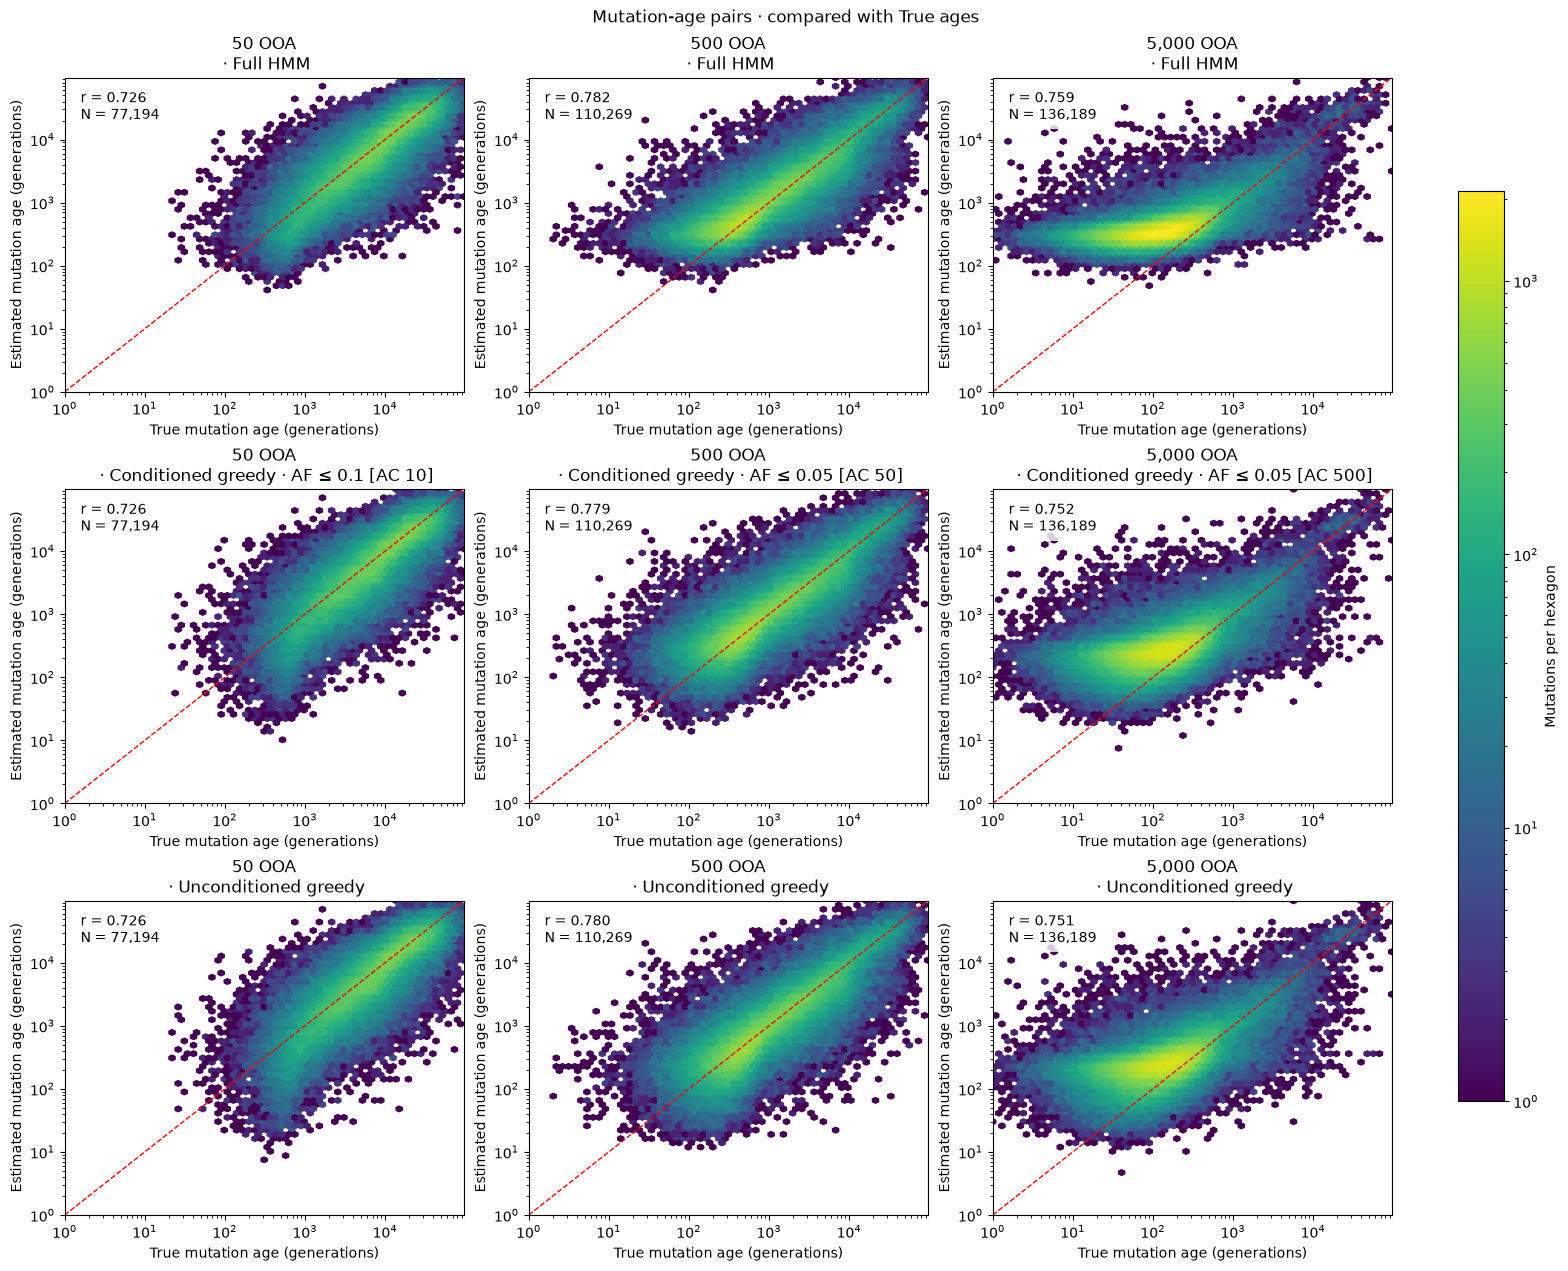

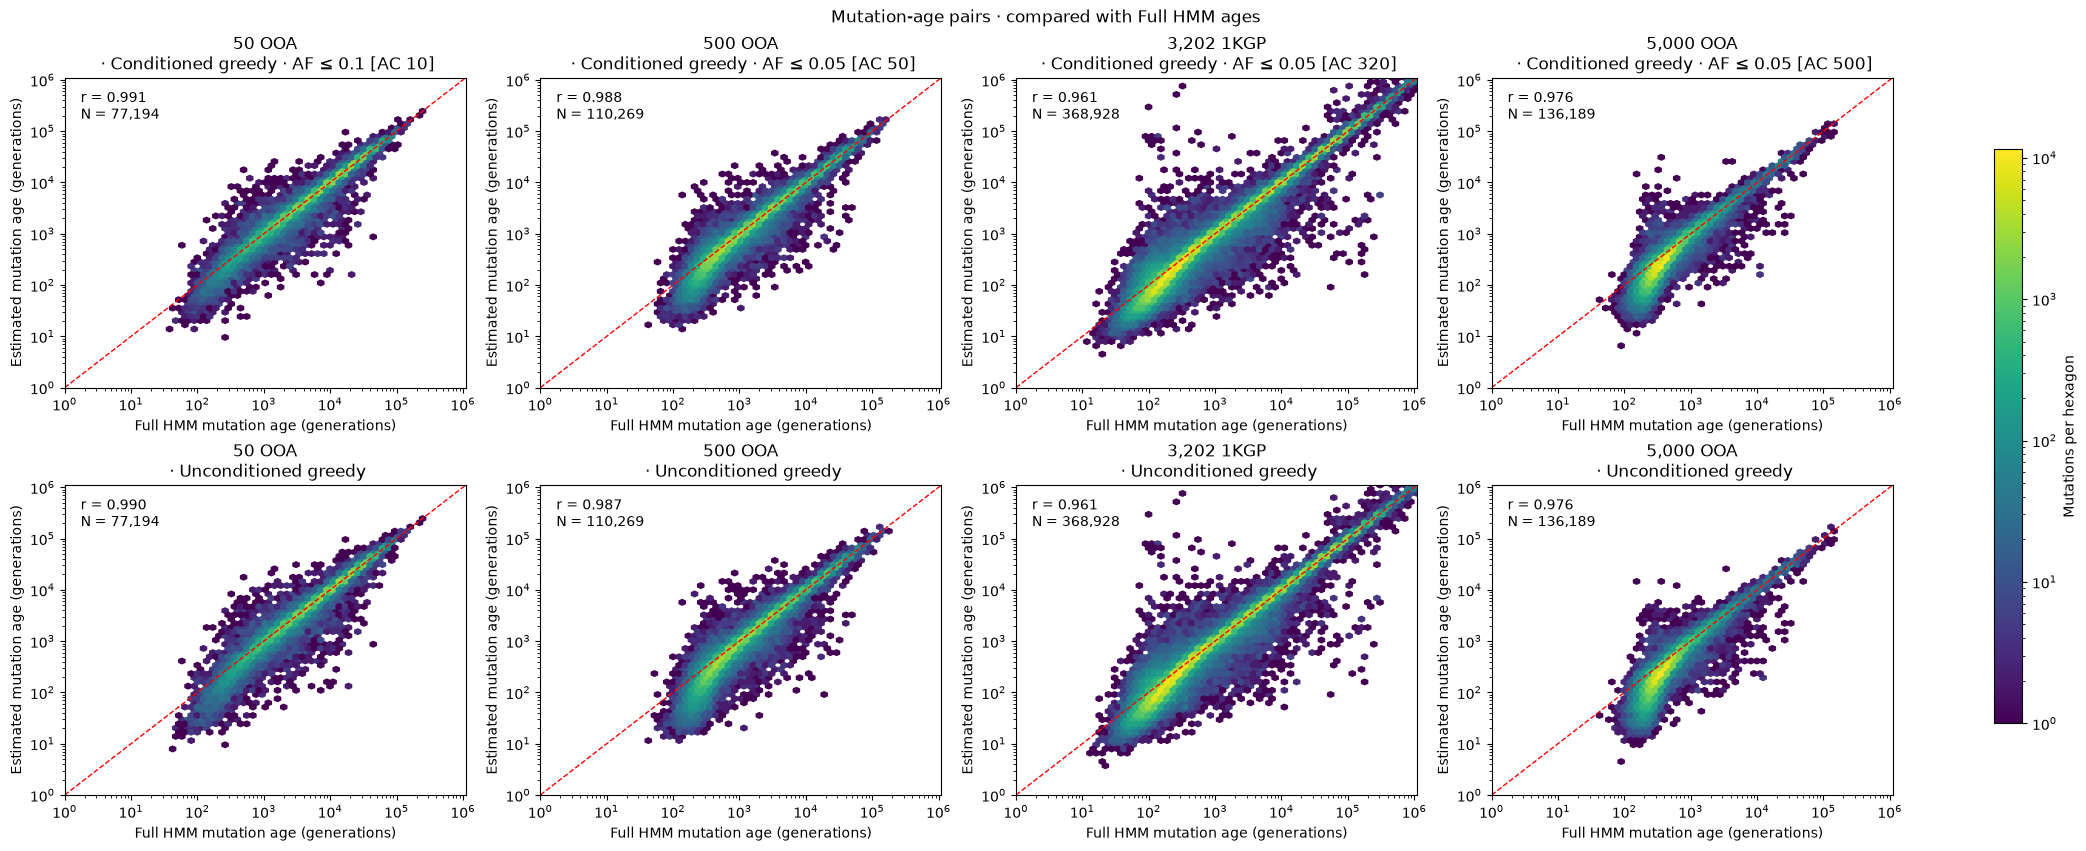

In [7]:
if __name__ == "__main__":
    for reference in ["truth", "full_hmm"]:
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_density(
                plot_data,
                age_correlations,
                reference,
                cohort_labels={
                    name: label + "\n" for name, label in cohort_labels.items()
                },
                method_labels=method_labels,
                method_colors=method_colors,
                panel_width=5.2,
                panel_height=4.2,
                age_hexbin_gridsize=65,
                age_maximum_quantile=0.999,
                age_minimum=1,
            ),
            f"conditioned_age_pairs_{reference}",
            export_dpi=180,
        )

## Performance: final optimisation trials only

These are the final 14 November trials after batched regional calls, native
numeric path assembly, regional tree seeking and overlapped input preparation.
There is one trial per dataset/method/mode with 96 matching workers; no
replicate uncertainty is implied. **From reference** includes preparation,
sample matching and finished output from an existing reference. **Resident
match** times matching/assembly with resident prepared inputs. Neither includes
upstream ancestor inference. These timers are kept separate.

The latest suite includes 1KGP. All 16 trials pass called-allele checks and
eight greedy outputs have exactly the corrected baseline edge/mutation arrays.
The archived optimisation logs report 688 TSLS checks and 55 pipeline checks
passing. Native sources were dirty; `source_snapshot/` and
`final_validation.json` beside the final trials preserve their identities.
This notebook reads those results without rebuilding dependencies or rerunning
their test suites. USS is sampled process-tree private memory; CPU/wall is
achieved average cores. The small cohorts can remain slower end to end even
when resident matching is faster. Cohorts have different settings and site
densities; connecting lines are visual guides, not controlled scaling curves.

,dataset,mode,method,wall_s,wall_ms_per_haplotype,speedup,effective_cores,window_peak_private_gib
0,out_of_africa_n50_28_1mbp_error,from_reference,greedy,4.9580,49.5803,0.6895,1.6136,1.5655
1,out_of_africa_n50_28_1mbp_error,from_reference,full_hmm,3.4186,34.1860,1.0000,4.1411,2.8719
2,out_of_africa_n50_28_1mbp_error,resident_match,greedy,0.1074,1.0745,1.8984,23.6100,0.0000
3,out_of_africa_n50_28_1mbp_error,resident_match,full_hmm,0.2040,2.0398,1.0000,55.0713,0.6042
4,out_of_africa_n500_28_1mbp_error,from_reference,greedy,15.4869,15.4869,0.8676,10.1333,6.8452
5,out_of_africa_n500_28_1mbp_error,from_reference,full_hmm,13.4358,13.4358,1.0000,33.8611,7.1450
6,out_of_africa_n500_28_1mbp_error,resident_match,full_hmm,4.9738,4.9738,1.0000,88.5230,7.1487
7,out_of_africa_n500_28_1mbp_error,resident_match,greedy,1.5255,1.5255,3.2604,77.4453,6.7674
8,out_of_africa_n5000_28_1mbp_error,from_reference,greedy,238.3208,23.8321,1.4229,44.5988,31.4617
9,out_of_africa_n5000_28_1mbp_error,from_reference,full_hmm,339.1087,33.9109,1.0000,80.2479,18.6411


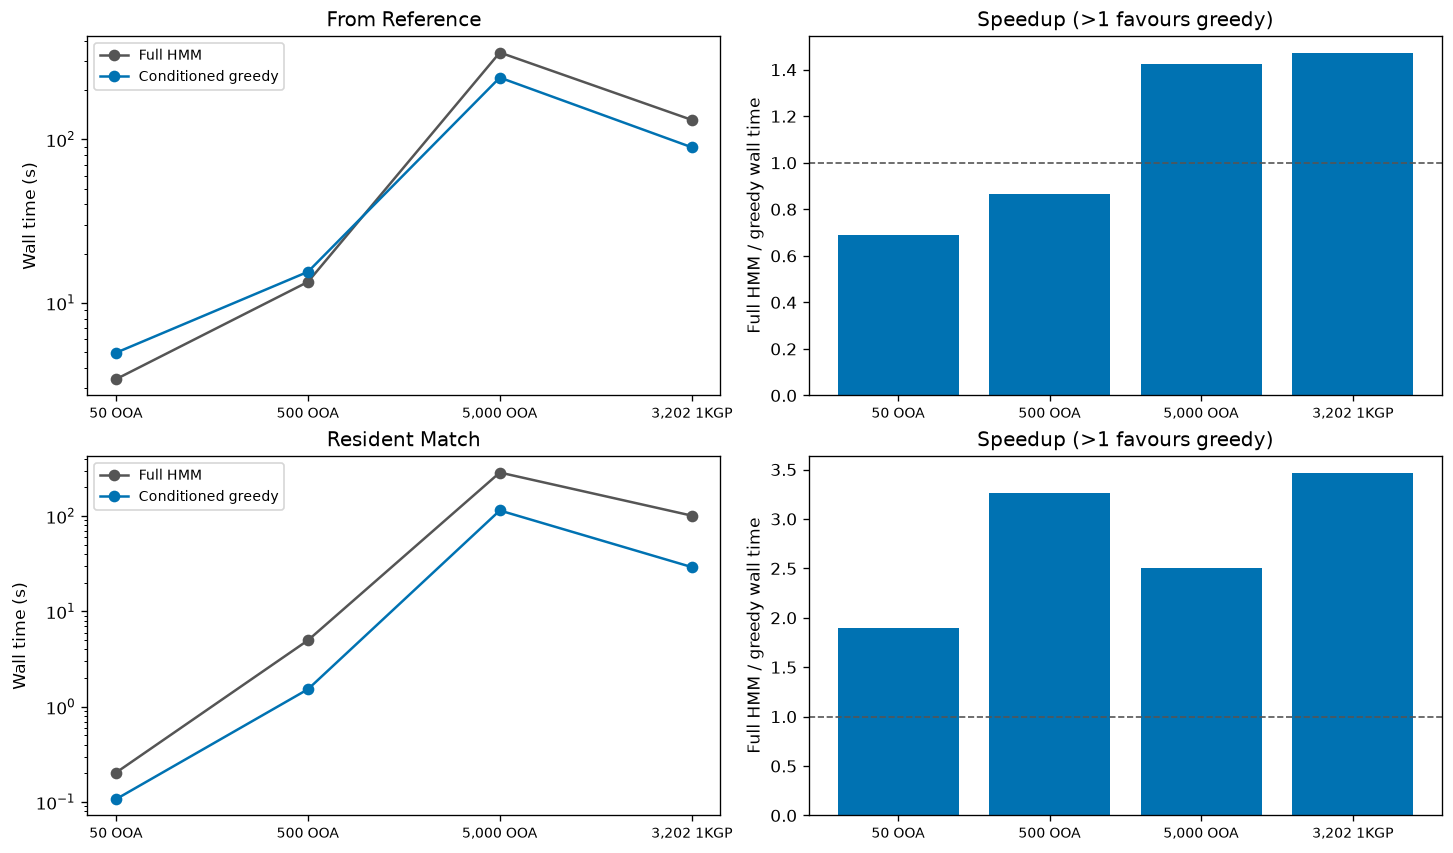

In [8]:
if __name__ == "__main__":
    performance = nb_utils.conditioning_review_performance(
        performance_dir, config["cache_dir"]
    )
    columns = [
        "dataset",
        "mode",
        "method",
        "wall_s",
        "wall_ms_per_haplotype",
        "speedup",
        "effective_cores",
        "window_peak_private_gib",
    ]
    ipython_display.display(performance[columns].round(4))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_conditioning_review_performance(
            performance,
            cohort_labels=cohort_labels,
            figsize=(12, 7),
            dpi=120,
            full_color="#555555",
            greedy_color="#0072B2",
        ),
        "latest_optimised_performance",
        export_dpi=180,
    )

## Interpretation of the matched control

Conditioning improves or preserves whole-span saved-path weight for every one of
the 17,504 paired haplotypes (numerical tolerance 1e-6 in log weight). Mean
conditioned minus unconditioned differences at the same epsilon are:

| Cohort | Log path weight | Terminal mutations | Parent switches |
| --- | ---: | ---: | ---: |
| out_of_africa_n50_28_1mbp_error | +471.22 | +32.16 | -48.78 |
| out_of_africa_n500_28_1mbp_error | +650.94 | +28.47 | -44.06 |
| out_of_africa_n5000_28_1mbp_error | +583.69 | +19.25 | -30.03 |
| tgp_chr20p_n3202 | +112.88 | +5.60 | -7.64 |

Full HMM remains the common whole-span baseline. Age statistics use one common
nonrecurrent mutation intersection across all three inferred methods and truth
where available. Read retention alongside age errors: recurrent and unpaired
mutations are excluded. Full HMM agreement in 1KGP is not a truth assessment.
Performance retains the original conditioned suite. There is no epsilon sweep.

## Deep dive: why the zero-recombination conditioned match was impossible

This is the **captured n50 failure**, not a toy example: `tsk_0`, haplotype 0,
job 0 in the 14 November replay log. The request covers inference sites
`[90955, 91213)` (258 sites including both pinned flanks). Its 256-site residual
gap lies between the left anchor at **26,656,210 bp** (parent **50854**) and the
right anchor at **26,758,466 bp** (parent **50856**). All **257 transitions**
between the included sites have recombination probability exactly zero.

Evidence below is preserved from `tmp/conditioning_numerics_20261114/`, including
the captured query, request, replay log and numerical controls. The Full HMM
comparator is the **original zero-map Full HMM tree** from the completed n50
trial; it passed its recorded called-allele check. It is not substituted by a
new full-sequence run. We also check the saved floored Full HMM and conditioned
greedy paths, and replay only this small window with native TSLS. No cohort
matching, ancestor inference, performance trials or dating runs here.

The simulation stores literal binary allele labels **0** and **1**. The figures
show these actual saved alleles, not invented nucleotide letters or parent IDs.
Every saved sample haplotype is checked against the complete captured query.

In [9]:
if __name__ == "__main__":
    failure_dir = (
        repository_dir
        / "data/ch5/stitching_pt12_conditioning/failure_deep_dive_20261116"
    )
    failure_data = nb_utils.conditioning_failure_analysis(
        config,
        evidence_dir=failure_dir / "evidence",
        output_dir=failure_dir,
        recombination_floor=1e-20,
        context_sites=12,
        diagnostic_mismatch=0.01,
    )
    ipython_display.display(pd.Series(failure_data.facts, name="value").to_frame())
    ipython_display.display(failure_data.replay_summary)
    archived_floor_controls = pd.read_json(
        failure_dir / "evidence/recombination_floor_controls.json"
    )
    ipython_display.display(archived_floor_controls)
    failure_config = dict(config)
    failure_config["cache_dir"] = failure_dir
    failure_plot_data = nb_utils.prepare_scaling_data(failure_config)

,value
dataset,out_of_africa_n50_28_1mbp_error
sample_id,tsk_0
ploidy_index,0
window_start_site,90955
window_end_site_exclusive,91213
window_sites_including_pins,258
interior_gap_sites,256
left_anchor_bp,26656210
right_anchor_bp,26758466
left_parent,50854


,case,recombination_floor,initial_state,final_state,mismatch_probability,status,switches,mismatches,parent_sequence,error
0,both_zero,0.000000e+00,50854.0,50856.0,1.929866e-07,MatchImpossible,NaN,NaN,No feasible path,Cannot recover the constrained path under the ...
1,left_only_zero,0.000000e+00,50854.0,NaN,1.929866e-07,ok,0.0,8.0,50854,
2,right_only_zero,0.000000e+00,NaN,50856.0,1.929866e-07,ok,0.0,10.0,50856,
3,unpinned_zero,0.000000e+00,NaN,NaN,1.929866e-07,ok,0.0,0.0,58721,
4,both_floor,1.000000e-20,50854.0,50856.0,1.929866e-07,ok,2.0,0.0,50854 → 58721 → 50856,
5,both_zero_more_mismatches,0.000000e+00,50854.0,50856.0,1.000000e-02,MatchImpossible,NaN,NaN,No feasible path,Cannot recover the constrained path under the ...


,recombination_floor,likelihood_threshold,prune_threshold,status,switches,mismatches,switch_odds
0,1.000000e-300,0,NaN,ok,1,8,1.000000e-302
1,1.000000e-100,0,NaN,ok,1,8,1.000000e-102
2,1.000000e-20,0,NaN,ok,2,0,1.000000e-22
3,1.000000e-16,0,NaN,ok,2,0,1.000000e-18
4,1.000000e-14,0,NaN,ok,2,0,1.000000e-16
5,1.000000e-12,0,NaN,ok,2,0,1.000000e-14
6,1.000000e-10,0,NaN,ok,2,0,1.000000e-12
7,1.000000e-08,0,NaN,ok,2,0,1.000000e-10


### Where the zeros originate, and what the two saved paths do

The original three-column HapMap source assigns rate **0 cM/Mb** at
**26,328,619 bp**, with the next map entry at **30,187,708 bp**. Integrating that
interval rate produces the archived cumulative-map plateau at approximately
**50.9869712 cM**. The failed window lies strictly inside this 3.86 Mb plateau.
There are no intervening map markers. This is what the supplied map assigns;
it does not establish that biological recombination is literally impossible
throughout the interval.

The helper verifies the normalized map against the original source, checks that
all 257 genetic distances are **exactly zero before** applying Haldane's
conversion, and confirms that the stable `-expm1(-2d)/2` expression is also zero.
This failure is therefore not caused by cancellation in `1 - exp(-2d)`, tiny
likelihood underflow, or pruning. The archived likelihood/pruning sweeps failed
too; the new replay keeps all three approximation thresholds at zero.

The original zero-map Full HMM stays on parent **58721** in this window. The
saved conditioned run with floor `1e-20` follows **50854 → 58721 → 50856**.
The latter can join the two fixed focal parents because the floor assigns a
positive probability to both otherwise forbidden changes. The replay is checked
against that saved path, and the zero-map and floored Full HMM paths are checked
to agree inside this window.

The final table above is the **archived local floor sensitivity diagnostic**,
not a new cohort experiment. At floors `1e-300` and `1e-100` the constrained
window has one switch and eight mismatches; at `1e-20` it has two switches and
zero mismatches. A positive floor repairs reachability, but its value also
changes the optimum. It is therefore a scientific parameter, not a harmless
way of avoiding a floating-point exception.

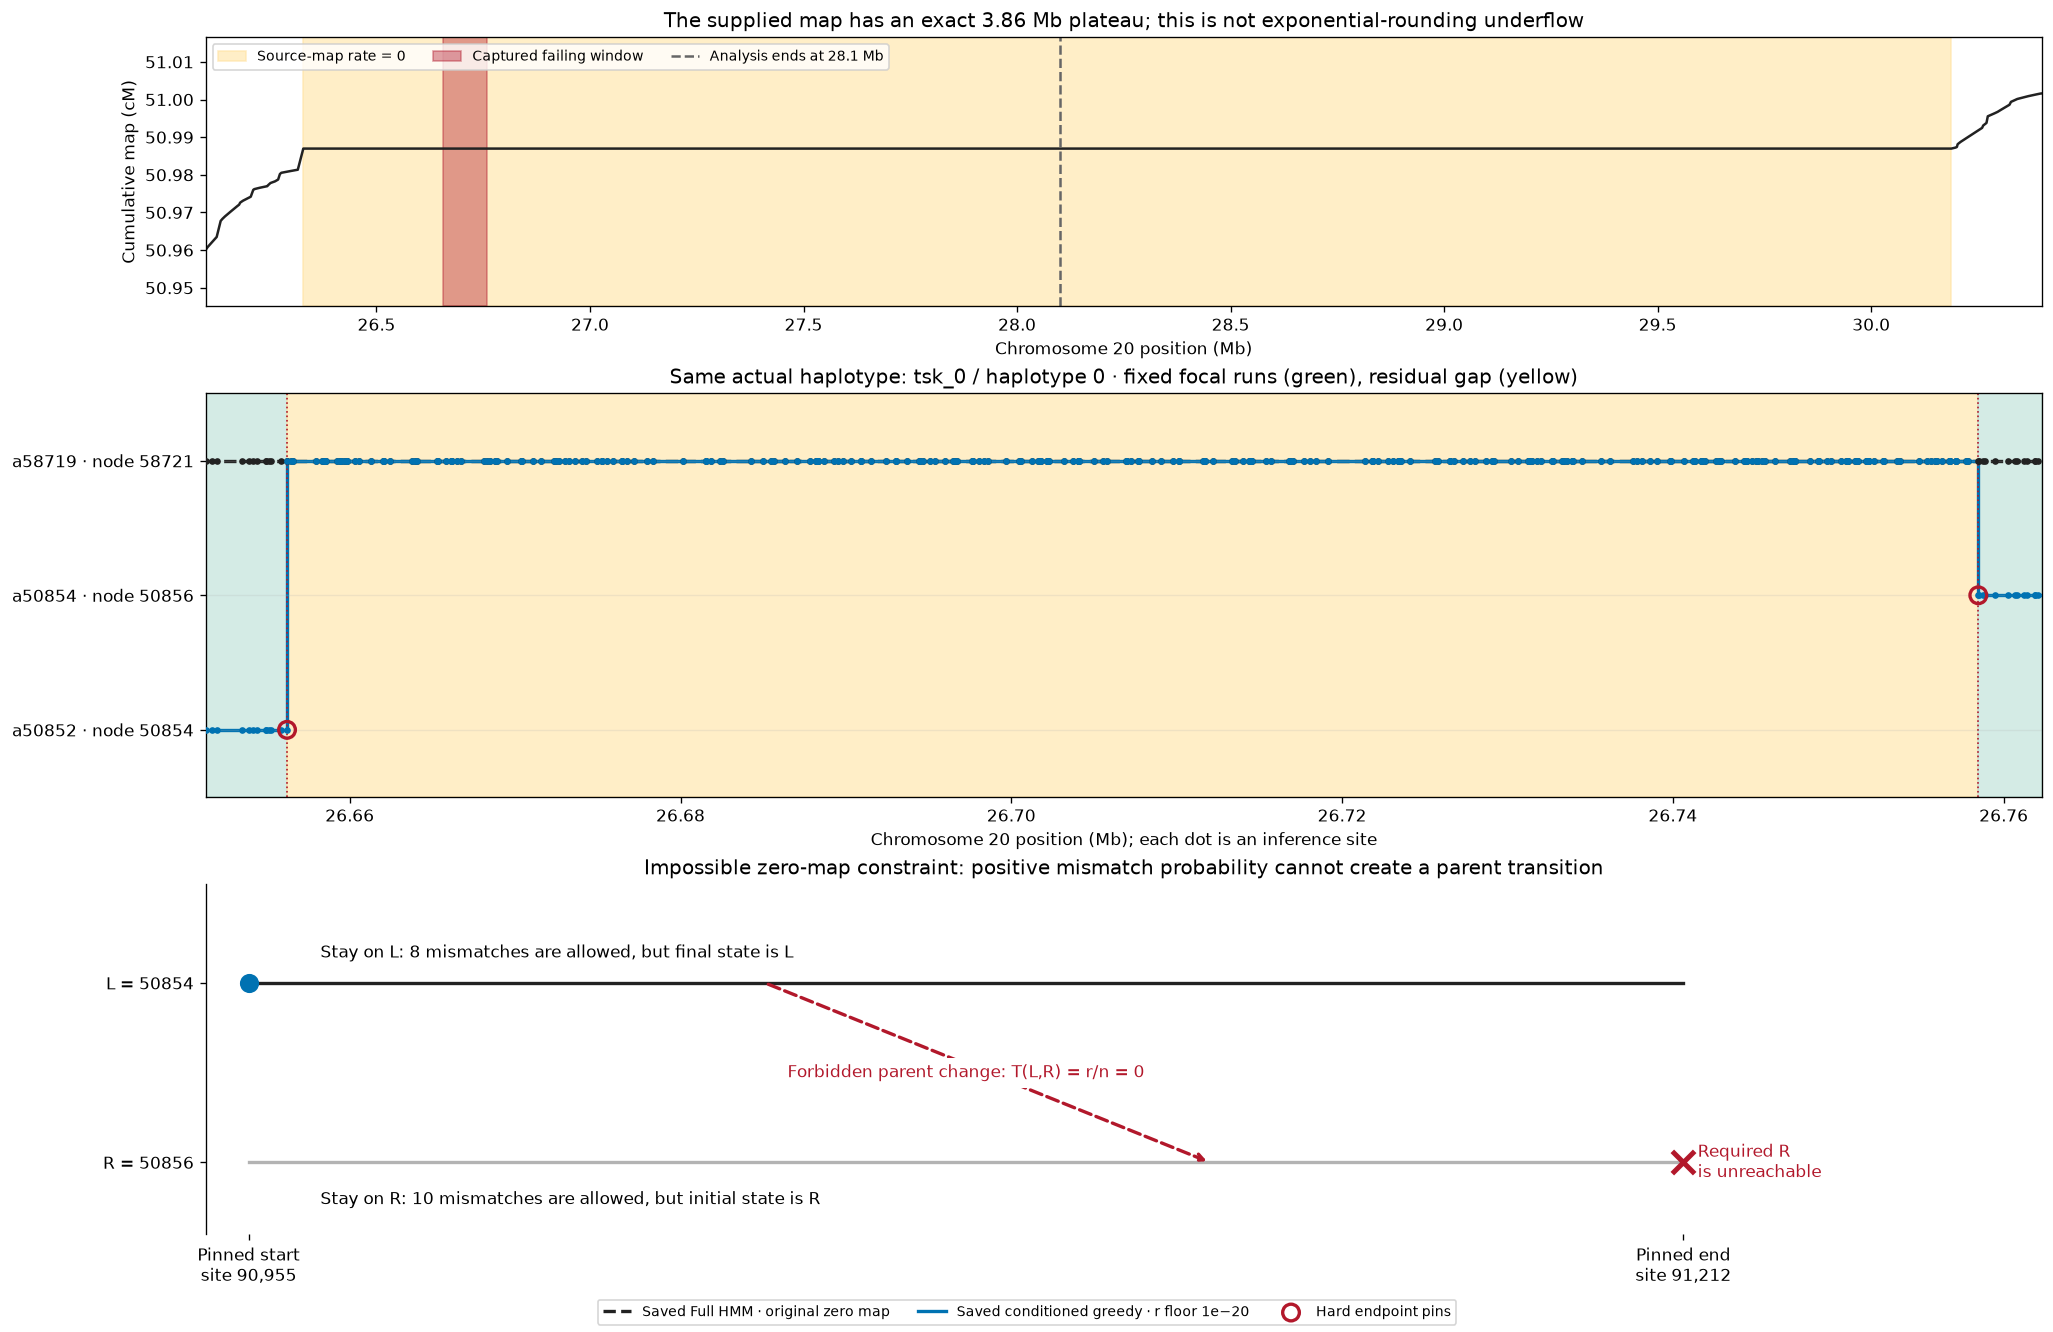

In [10]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        failure_plot_data,
        nb_plot.plot_conditioning_failure_overview(
            failure_data,
            figsize=(17, 11),
            dpi=120,
            map_limits_mb=(26.1, 30.4),
            analysis_end_bp=28100000,
            full_color="#222222",
            floor_color="#0072B2",
            impossible_color="#B2182B",
            focal_color="#B8DED4",
            gap_color="#FFE3A3",
        ),
        "zero_recombination_failure_overview",
        export_dpi=180,
    )

### Why adding mismatches cannot rescue both endpoint constraints

A mismatch is an **emission**: the sample can differ from the allele of the
parent it continues to copy. It does not change which parent is copied.
For this HMM, the transition weights are

\[
T_i(u,v)=\begin{cases}1-r_i+r_i/n,&u=v,\\r_i/n,&u\ne v.\end{cases}
\]

Here `r_i = 0`, so staying has weight 1 and changing parent has weight 0.
The original mismatch probability is positive (about `1.93e-7`), so any finite
number of mismatches has a positive emission weight. But a path from pinned
parent **50854** to different pinned parent **50856** must contain at least one
parent change. Its transition product is zero regardless of how many mismatches
we allow: **positive emission weight × zero transition weight = zero**.

The one-sided replays show the distinction directly. Keeping only the left pin
allows TSLS to stay on 50854 and add **eight mismatches**; keeping only the right pin
allows it to stay on 50856 and add **ten mismatches**. Neither constant path satisfies
both pins. Even raising the diagnostic mismatch probability to `0.01` leaves
the two-pin zero-map match impossible. The table reports `MatchImpossible`
rather than inventing a returned path. The dotted red line in the allele panels
is the successful **left-pin-only diagnostic**, whose final parent violates the
original right pin; it is not a solution of the failed request.

In native TSLS, `tsls_hmm_seed_initial_state` gives the initial parent finite
cost and the other states infinite cost. A zero-rate transition cannot reach
the required final parent, and the constrained traceback rejects its infinite
cost (`tsls/lib/hmm.c`, initial-state seeding and final-state traceback). The
error is the mathematically correct response to these constraints.

The pins constrain **reference node identity**, not merely the allele at the
anchor. At both actual anchor sites the sample and all three displayed parents
have allele **0**. Matching that allele with parent 58721 is entirely possible
and is what Full HMM does; it still does not satisfy a hard pin to parent 50854
or 50856. Mutations can change the emitted allele, not the identity of the
copying state.

There is also a particularly clear unconstrained solution here: parent **58721**
matches **all 258 observed alleles with zero mismatches and zero switches**.
That is the original Full HMM path in this window. The failure does not indicate
that TSLS has run out of matching haplotypes. All six diagnostic outcomes were
also reproduced in the pipeline's installed TSLS runtime, independently of the
notebook analysis runtime.

### Actual haplotypes, all 258 sites

These panels use the same categorical-parent path convention as Part 1, with
**every actual 0/1 allele printed below it**. Equal-width columns are inference
sites, not equal physical distances; both site indices and physical coordinates
are labelled. Open circles and blue-tinted columns identify the two pinned
flanking sites. Red frames identify reference/copied alleles differing from the
captured sample. The complete site-by-site table is exported as
`actual_haplotypes.csv`, including each method's parent and copied allele.

The Full HMM and floored greedy copied-allele rows can agree even while their
parent IDs differ. Conversely, accepting mismatches on a fixed parent does not
make it possible to jump to the other endpoint parent.

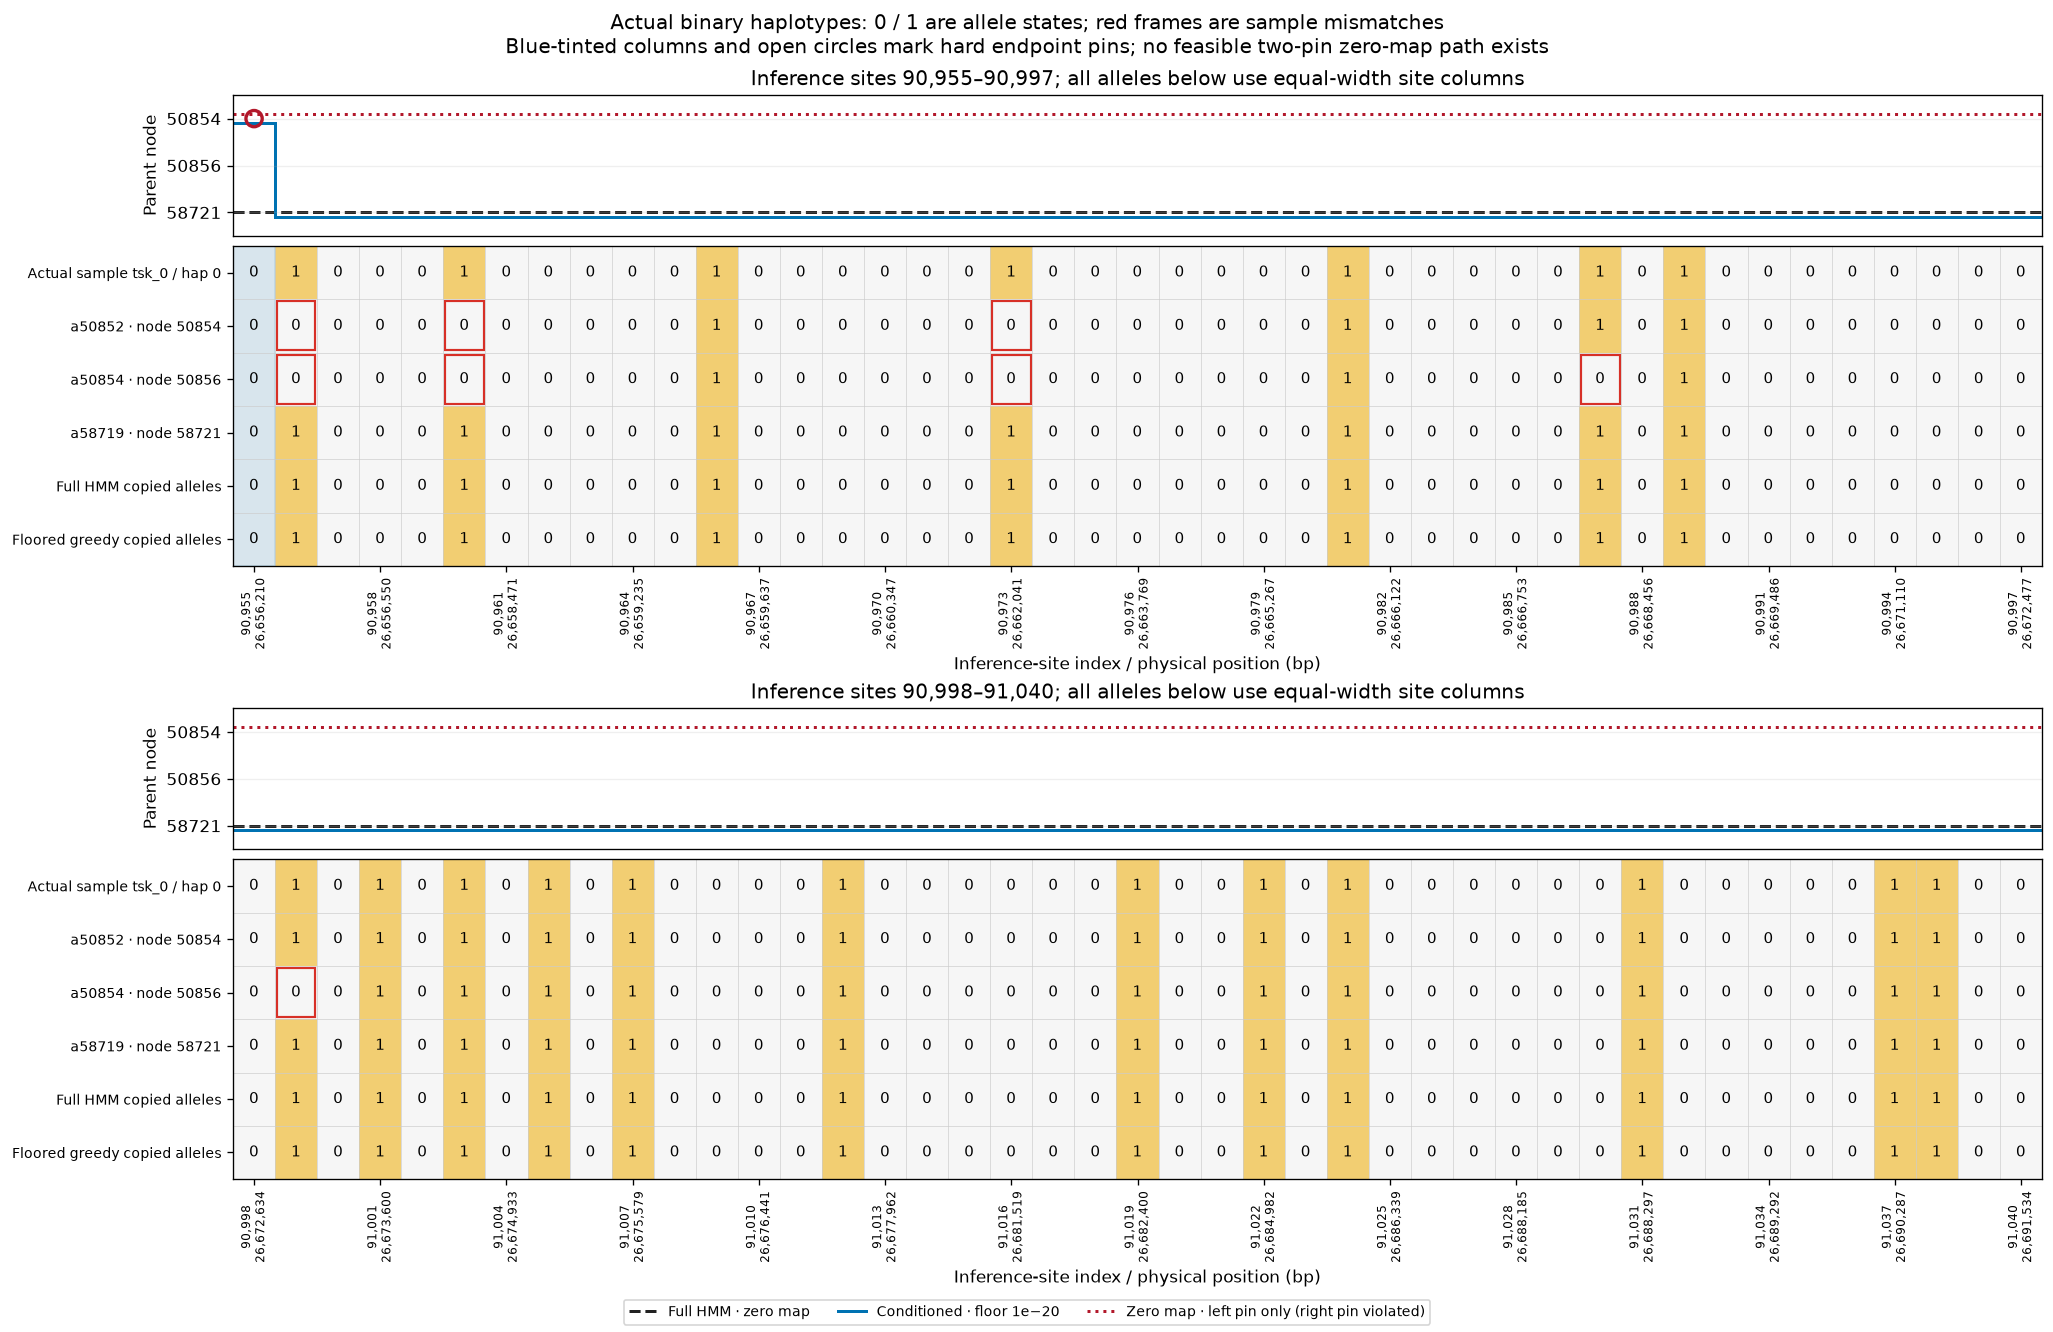

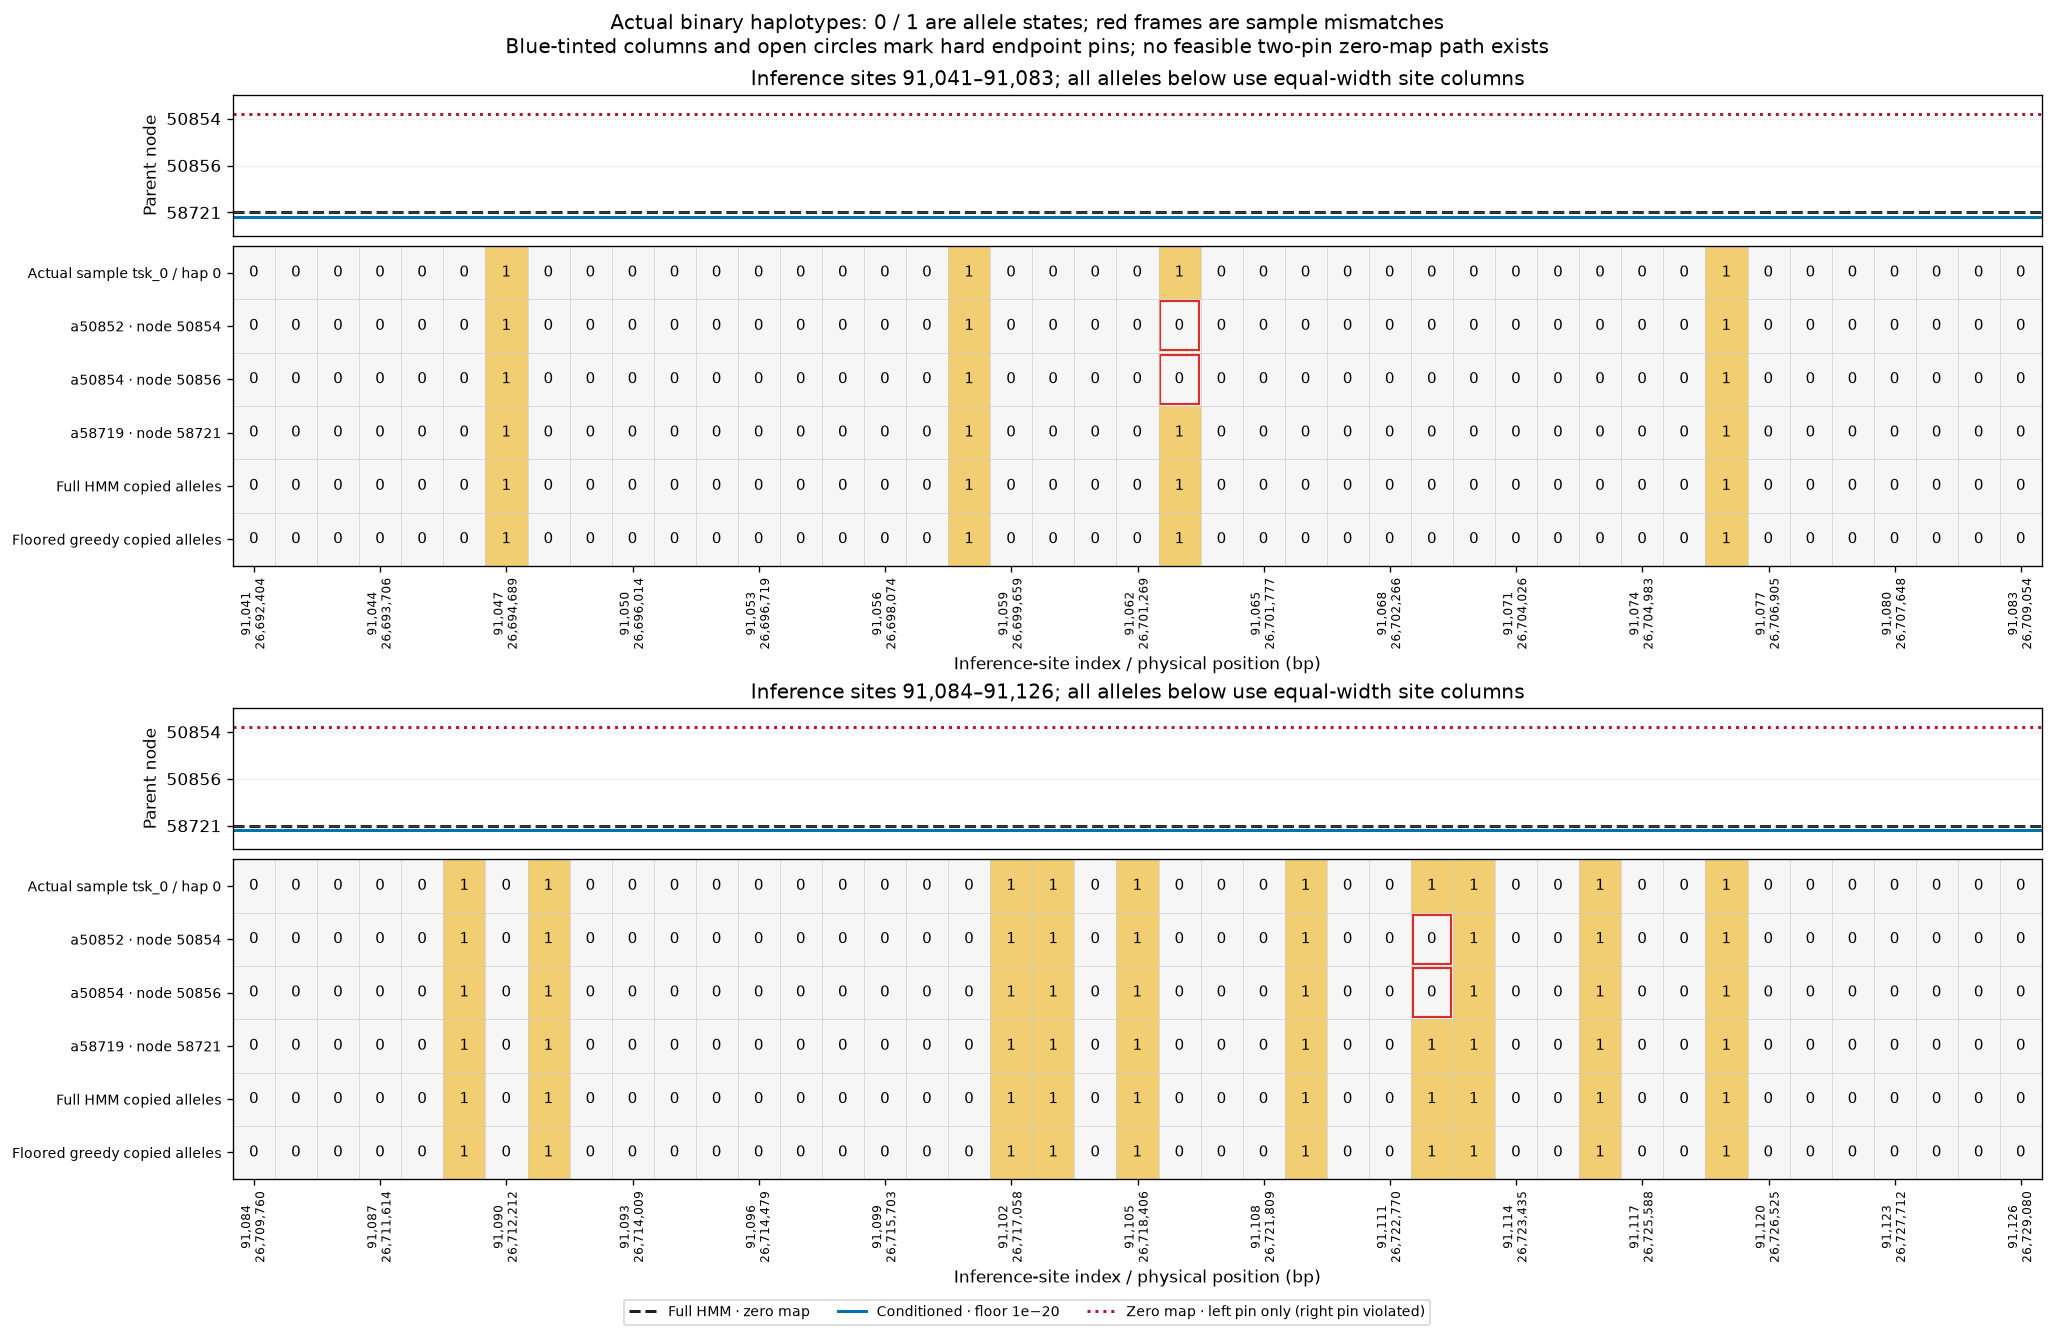

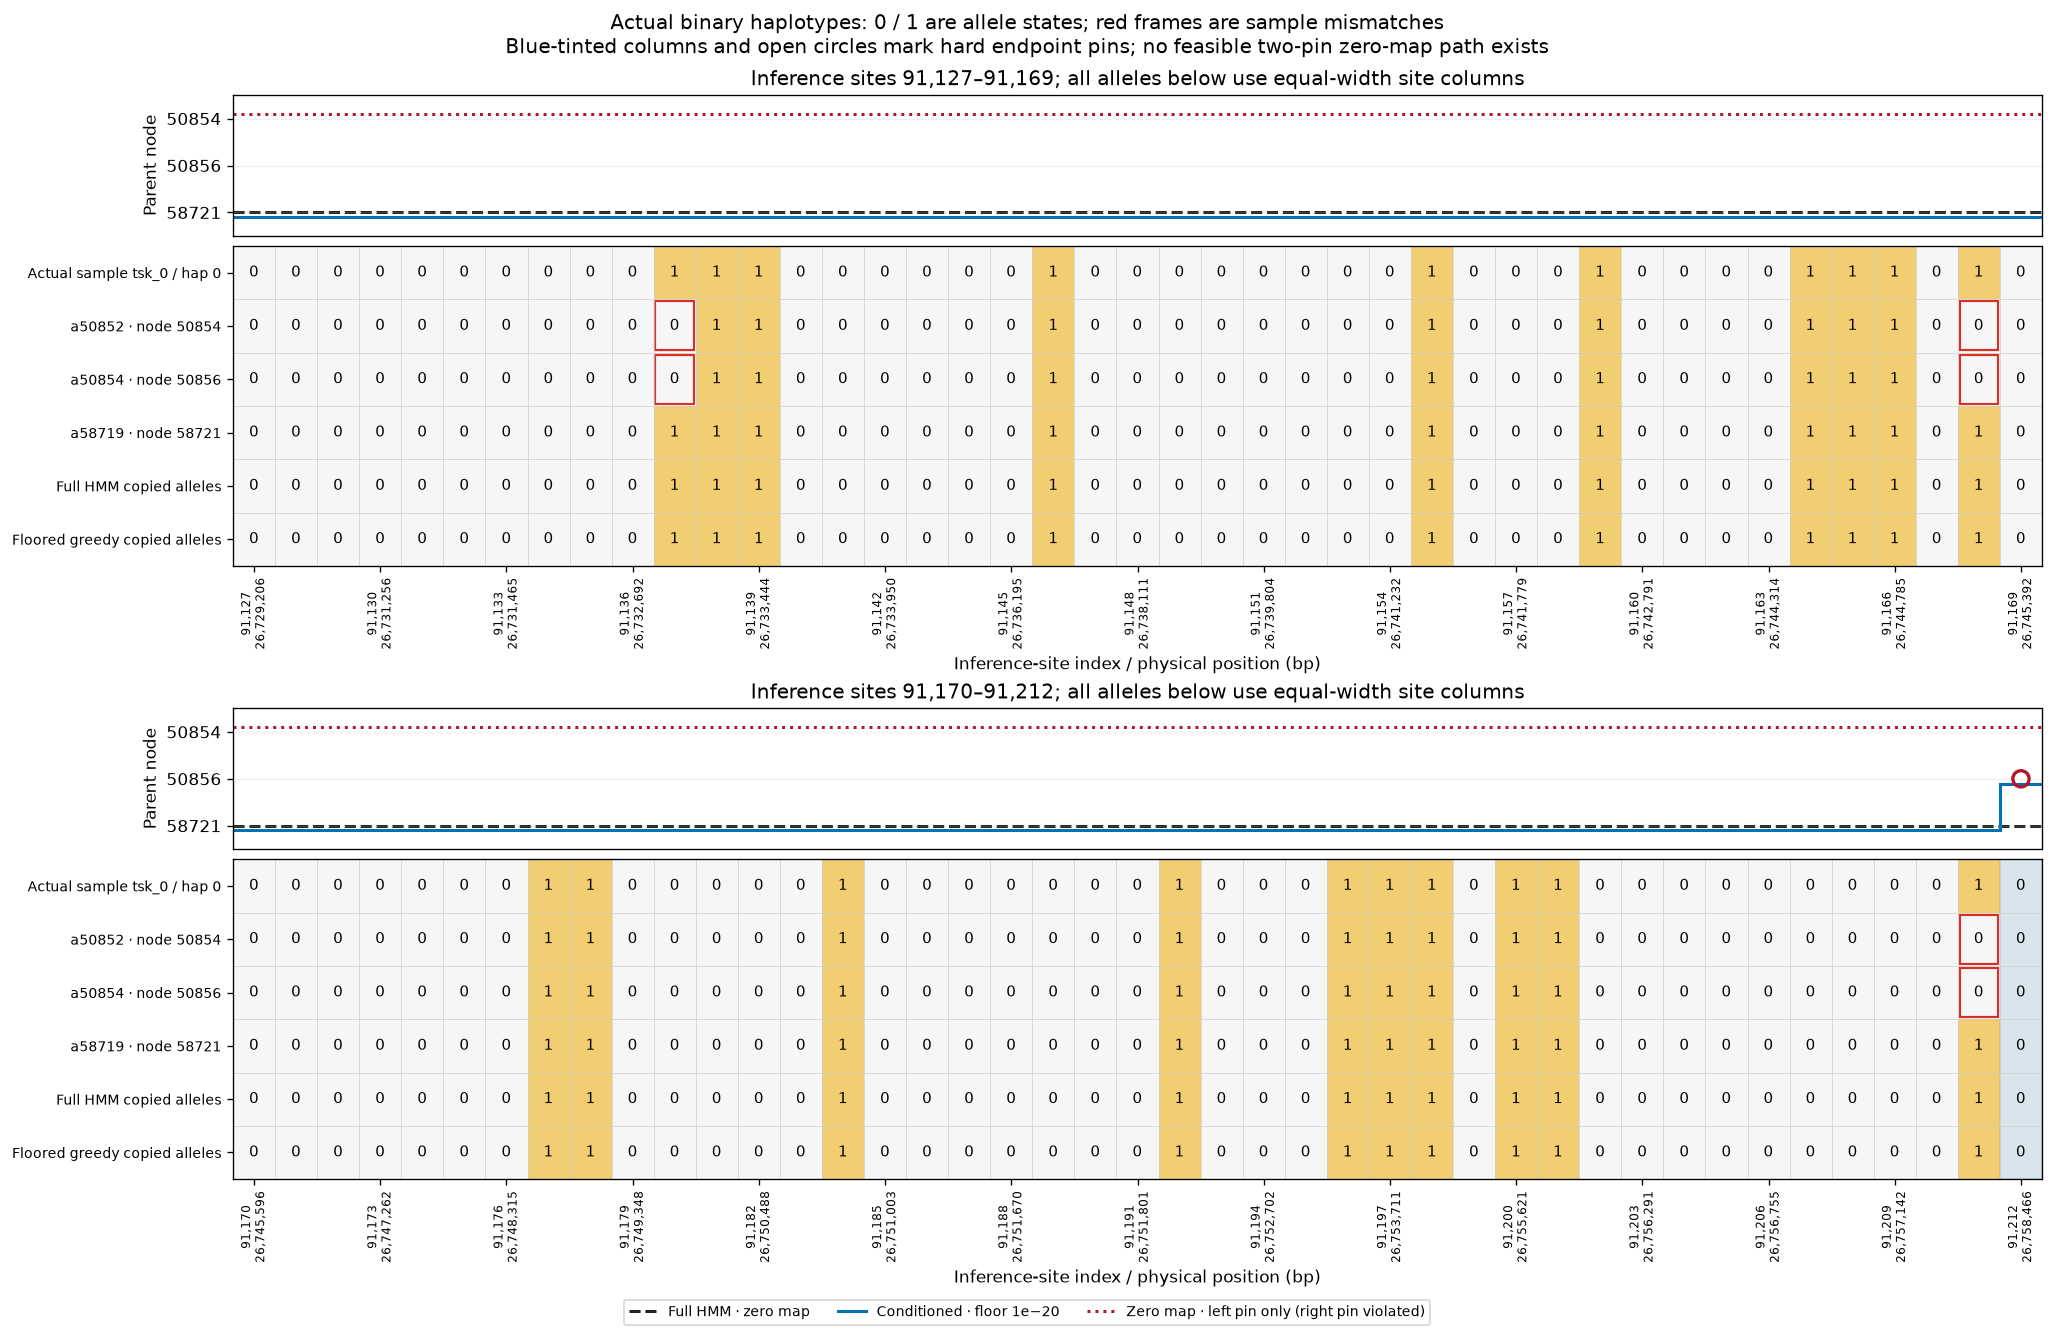

In [11]:
if __name__ == "__main__":
    sites_per_panel = 43
    sites_per_figure = 86
    for number, start_site in enumerate(
        range(
            failure_data.request["start"], failure_data.request["end"], sites_per_figure
        ),
        start=1,
    ):
        end_site = min(start_site + sites_per_figure, failure_data.request["end"])
        nb_plot.save_cohort_figure(
            failure_plot_data,
            nb_plot.plot_conditioning_failure_alleles(
                failure_data,
                start=start_site,
                end=end_site,
                columns=sites_per_panel,
                figsize=(17, 11),
                dpi=120,
                full_color="#222222",
                floor_color="#0072B2",
                impossible_color="#B2182B",
                allele_colors=("#F6F6F6", "#F2CE72", "#D9D9D9"),
                mismatch_edge_color="#D73027",
                allele_fontsize=9,
                coordinate_fontsize=7,
            ),
            f"zero_recombination_actual_haplotypes_{number}",
            export_dpi=180,
        )

### What would avoid specifying a recombination floor?

If the supplied zero rates are retained, the greedy constraints must admit a
path under that model. In this example a valid alternative is the Full HMM's
single parent 58721 through the window, accepting whatever mismatches are
necessary. That requires reconsidering the adjoining fixed focal choices,
not merely changing the number of mutations inside the gap.

A principled no-floor implementation would detect connected runs of zero-rate
transitions and choose compatible copying/focal states across the whole block
(or rematch an expanded region while permitting the conflicting focal choices
to change). Checking only each gap independently is insufficient: fixed focal
runs can themselves require forbidden switches inside the same zero-map block.
This needs an explicit matching-policy change and is not implemented by this
investigation.

Simply dropping one endpoint when a gap fails would make the regional call
succeed, but stitching it back to a different fixed parent can reintroduce a
zero-probability switch at the seam. It is therefore not a valid silent repair
of the unchanged whole-span model. Alternatively, supplying a map with justified
positive rates changes the model; the `1e-20` floor is one such change, not a
numerically neutral stabilizer. No floor is needed for an unconstrained match
of this captured window. The incompatibility is **different hard parent pins
inside an exactly zero-transition block**, not an inability to tolerate poor
allelic matches.